# Agentic vs classic pipeline: results notebook

Analyses the runs produced by `run_models.sh`. One folder per model, for example `runs/gemma-4-26b-a4b/`, containing `timing.csv`, `llm_calls.jsonl`, `trace.jsonl`,`comparison/{per_hour,per_node}.csv`, `comparison/summary.json` and optionally `logs/`.


| Priority | Section | Question |
|---|---|---|
| 1 | Workflow and prediction fidelity | Does agentic orchestration preserve the deterministic operations? |
| 2 | Traffic classification agreement | Do agents reproduce the expected verdicts (node, corridor, network)? |
| 3 | Failure and disagreement analysis | Why do the agents differ from the baseline? |
| 4 | Execution time | Is hourly operation feasible? |
| 5 | LLM resource consumption | Tokens, context, summarisation, turns, errors |
| 6 | Five-year cost | Local hardware vs API, break-even |

Every table is also written to `analysis_out/` as CSV.

In [121]:
import json, re, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import cohen_kappa_score
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# ------------------------------ configuration ------------------------------ #
RUNS = {
    "Gemma (subagents) run 1": "runs/gemma-4-26b-a4b",
    "Gemma (subagents) run 2": "runs_2/gemma-4-26b-a4b",
    "Gemma (no subagents) run": "no_subagents/runs_no_subagents/gemma-4-26b-a4b_nosub",
    "Qwen (subagents) run 1":  "runs/qwen3.8-27b",
    "Qwen (subagents) run 2":  "runs_2/qwen3.8-27b",  
    "Qwen (no subagents) run":  "no_subagents/runs_no_subagents/qwen3.8-27b_nosub",    
}

CLASSIC_DIR   = "runs/classic_ref/classic"  # hour_*.json written by classic_runner.py
CONTEXT_LIMIT = 24000                       # GOOSE_CONTEXT_LIMIT
MAX_TURNS     = 150                         # GOOSE_MAX_TURNS
STALL_S       = 300                         # a single LLM request slower than this counts as a stall
RUNAWAY_TOKENS = 20000                      # a single response longer than this counts as a runaway
FEASIBLE_S    = 3600                        # hourly operation: a session must finish within this
OUT = Path("analysis_out"); OUT.mkdir(exist_ok=True)

# ------------------------------ chart styling ------------------------------ #
INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
COLORS = {"Gemma": "#2a78d6", "Qwen": "#eb6834", "Classic": "#8a8984"}   # fixed order: blue, orange, gray
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.6, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "regular",
    "legend.frameon": False, "figure.dpi": 110,
})
pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 80)

def show(df, title, name=None, index=True):
    display(Markdown(f"**{title}**"))
    display(df)
    if name:
        df.to_csv(OUT / f"{name}.csv", index=index)

## Load data

In [122]:
def read_jsonl(path):
    rows = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError:
                    pass
    return pd.DataFrame(rows)

CALL_COLS = ["prompt_tokens", "completion_tokens", "latency_s", "ttft_s", "retries", "queue_wait_s",
             "n_messages", "cached_tokens", "status"]

def load_run(name, path):
    p = Path(path)
    if not (p / "timing.csv").exists():
        return None
    r = {"name": name, "path": p}
    r["timing"] = pd.read_csv(p / "timing.csv").drop_duplicates("hour", keep="last").reset_index(drop=True)
    calls = read_jsonl(p / "llm_calls.jsonl") if (p / "llm_calls.jsonl").exists() else pd.DataFrame()
    for c in CALL_COLS:
        if c not in calls:
            calls[c] = np.nan
    for c in ("finish_reason", "error", "usage_source", "hour"):
        if c not in calls:
            calls[c] = None
    if "summarize_hint" not in calls:
        calls["summarize_hint"] = False
    calls = calls[calls.hour.isin(r["timing"].hour)].copy()
    calls["summarize_hint"] = calls.summarize_hint.fillna(False).astype(bool)
    r["calls"] = calls
    r["trace"] = read_jsonl(p / "trace.jsonl") if (p / "trace.jsonl").exists() else pd.DataFrame()
    cmp_dir = p / "comparison"
    r["per_hour"] = pd.read_csv(cmp_dir / "per_hour.csv") if (cmp_dir / "per_hour.csv").exists() else None
    r["per_node"] = pd.read_csv(cmp_dir / "per_node.csv") if (cmp_dir / "per_node.csv").exists() else None
    sj = cmp_dir / "summary.json"
    r["summary"] = json.loads(sj.read_text()) if sj.exists() else {}
    if r["per_hour"] is not None:
        r["ph_last"] = r["per_hour"][r["per_hour"].session_is_last_for_hour.astype(bool)].copy()
    return r

def load_classic(directory):
    recs = {}
    for p in sorted(Path(directory).glob("hour_*.json")):
        j = json.loads(p.read_text())
        if j.get("hour") and not j.get("fatal_error"):
            recs[pd.Timestamp(j["hour"]).isoformat()] = j
    return recs

R = {n: r for n, p in RUNS.items() if (r := load_run(n, p))}
CLASSIC = load_classic(CLASSIC_DIR) if Path(CLASSIC_DIR).exists() else {}
assert R, "no run folder found: check RUNS at the top"
rows = [{"run": n, "sessions (timing.csv)": len(r["timing"]), "LLM requests": len(r["calls"]),
         "trace records": len(r["trace"]), "per_hour rows": None if r["per_hour"] is None else len(r["per_hour"]),
         "per_node rows": None if r["per_node"] is None else len(r["per_node"])} for n, r in R.items()]
show(pd.DataFrame(rows).set_index("run"), f"Loaded runs (classic reference: {len(CLASSIC)} hours)")

**Loaded runs (classic reference: 169 hours)**

,sessions (timing.csv),LLM requests,trace records,per_hour rows,per_node rows
run,,,,,
Gemma (subagents) run 1,169,21182,22430,169,2028
Gemma (subagents) run 2,169,20981,22802,170,2028
Gemma (no subagents) run,169,24988,48938,169,2016
Qwen (subagents) run 1,169,15472,20540,169,2028
Qwen (subagents) run 2,169,16601,22310,169,2028
Qwen (no subagents) run,169,7768,26300,169,2028


## 1. Workflow and prediction fidelity (essential)

Reference = the classic run (same models, same data). Call-level counts use every agent session;
node-hour comparisons use the last session of each hour.

In [123]:
def num(s):
    return pd.to_numeric(s, errors="coerce")

def share(a, b):
    return None if not b else round(a / b, 4)

def fidelity(r):
    ph, last, pn = r["per_hour"], r["ph_last"], r["per_node"]
    t = r["timing"]
    d = {}
    exit_ok = t.goose_exit.astype(str).eq("0").sum()
    complete = (last.log_run_summary_ok.astype(bool) & last.log_final_ditto_ok.astype(bool)).sum()
    d[("Sessions", "classic hours in the reference")] = len(CLASSIC) or None
    d[("Sessions", "agent sessions run")] = len(t)
    d[("Sessions", "goose exit code 0")] = f"{exit_ok} ({share(exit_ok, len(t))})"
    d[("Sessions", "completed (run summary + final Ditto logged)")] = f"{complete} ({share(complete, len(last))})"
    d[("Sessions", "repeated sessions for an hour")] = len(ph) - len(last)
    bst = last.build_summary_table_ok
    d[("Sessions", f"build_summary_table succeeded for both corridors")] = f"{(bst >= 2).sum()} of {len(last)}"
    d[("Sessions", "build_summary_table succeeded for no corridor")] = f"{(bst == 0).sum()} of {len(last)}"
    # coverage
    cl = int(last.classic_logged.sum()); ag = int(last.agent_logged.sum())
    miss = int(last.missing_nodes.fillna("").map(lambda s: len(s.split())).sum())
    extra = int(last.extra_nodes.fillna("").map(lambda s: len(s.split())).sum())
    d[("Prediction coverage", "node-hours classic predicted")] = cl
    d[("Prediction coverage", "node-hours agent predicted")] = ag
    d[("Prediction coverage", "mean coverage vs classic")] = round(last.coverage_vs_classic.mean(), 4)
    d[("Prediction coverage", "missing node-hours")] = f"{miss} ({share(miss, cl)})"
    d[("Prediction coverage", "extra node-hours")] = extra
    d[("Prediction coverage", "sessions with full coverage")] = f"{(last.coverage_vs_classic == 1).sum()} of {len(last)}"
    # input correctness
    calls = int(ph.baseline_predict_calls.sum()); bad = int(ph.payload_bad_calls.sum())
    d[("Input correctness", "baseline_predict calls")] = calls
    d[("Input correctness", "calls with a wrong payload")] = f"{bad} ({share(bad, calls)})"
    d[("Input correctness", "get_flows calls for the wrong hour")] = int(ph.get_flows_wrong_hour.sum())
    d[("Input correctness", "calls to nodes that should not be touched")] = int(ph.unexpected_node_calls.sum())
    # prediction agreement
    both = pn[num(pn.abs_diff).notna()]
    d[("Prediction agreement", "node-hours compared")] = len(both)
    d[("Prediction agreement", "exact match (|diff| <= tol)")] = share(int(both.pred_match.astype(bool).sum()), len(both))
    d[("Prediction agreement", "mean abs diff (veh/h)")] = round(num(both.abs_diff).mean(), 4)
    d[("Prediction agreement", "max abs diff (veh/h)")] = round(num(both.abs_diff).max(), 4)
    wa = pn[num(pn.smape_agent).notna() & num(pn.smape_classic).notna()]
    d[("Forecast accuracy vs observed", "mean SMAPE classic")] = round(num(wa.smape_classic).mean(), 4)
    d[("Forecast accuracy vs observed", "mean SMAPE agent")] = round(num(wa.smape_agent).mean(), 4)
    d[("Forecast accuracy vs observed", "share of node-hours where agent is worse")] = share(
        int((num(wa.smape_agent) > num(wa.smape_classic) + 1e-9).sum()), len(wa))
    # evaluation correctness
    ev = last[last.evaluation_expected.astype(bool)]
    cd = int(ph.check_deviation_calls.sum()); cdb = int(ph.check_deviation_bad_args.sum())
    d[("Evaluation correctness", "sessions where an evaluation was expected")] = len(ev)
    d[("Evaluation correctness", "mean evaluation coverage vs classic")] = round(ev.eval_coverage_vs_classic.mean(), 4)
    d[("Evaluation correctness", "check_deviation calls")] = cd
    d[("Evaluation correctness", "check_deviation calls with wrong arguments")] = f"{cdb} ({share(cdb, cd)})"
    d[("Evaluation correctness", "overall verdict matches classic")] = share(int(last.overall_verdict_match.astype(bool).sum()), len(last))
    d[("Evaluation correctness", "run-summary counts match classic")] = share(int(last.summary_counts_match.astype(bool).sum()), len(last))
    return d

fid = pd.DataFrame({n: fidelity(r) for n, r in R.items() if r["per_hour"] is not None})
fid.index.names = ["Area", "Metric"]
show(fid, "Workflow and prediction fidelity", "1_fidelity")

**Workflow and prediction fidelity**

Gemma (subagents) run 1 Gemma (subagents) run 2 Gemma (no subagents) run Qwen (subagents) run 1 Qwen (subagents) run 2  \
Area                          Metric                                                                                                                                                                    
Sessions                      classic hours in the reference                                       169                     169                      169                    169                    169   
                              agent sessions run                                                   169                     169                      169                    169                    169   
                              goose exit code 0                                              169 (1.0)               169 (1.0)             167 (0.9882)              169 (1.0)              169 (1.0)   
                              completed (run summary + final Ditto logged)                   169 (1.0)            167 (0.9882)                1 (0.006)           164 (0.9704)           164 (0.9704)   
                              repeated sessions for an hour                                          0                       1                        1                      0                      0   
                              build_summary_table succeeded for both corridors               90 of 169               87 of 169                 1 of 168             164 of 169             164 of 169   
                              build_summary_table succeeded for no corridor                  32 of 169               43 of 169               163 of 168               5 of 169               4 of 169   
Prediction coverage           node-hours classic predicted                                        2028                    2028                     2016                   2028                   2028   
                              node-hours agent predicted                                          1936                    1938                     1572                   1754                   1880   
                              mean coverage vs classic                                          0.9546                  0.9556                   0.7798                 0.8649                  0.927   
                              missing node-hours                                           92 (0.0454)             90 (0.0444)             444 (0.2202)           274 (0.1351)            148 (0.073)   
                              extra node-hours                                                       0                       0                        0                      0                      0   
                              sessions with full coverage                                   117 of 169              117 of 169                12 of 168              96 of 169             126 of 169   
Input correctness             baseline_predict calls                                              2101                    2103                     4742                   1891                   2007   
                              calls with a wrong payload                                  162 (0.0771)            156 (0.0742)             390 (0.0822)            16 (0.0085)             9 (0.0045)   
                              get_flows calls for the wrong hour                                     0                       0                        0                      2                      2   
                              calls to nodes that should not be touched                              0                       0                        0                      0                      0   
Prediction agreement          node-hours compared                                                 1930                    1938                     1570                   1751                   1879   
                              exact match (|diff| <= tol)  

In [124]:
for name in [
    "Gemma (no subagents) run",
    "Qwen (no subagents) run"
]:
    calls = R[name]["calls"]

    flagged = calls[calls.summarize_hint]

    print(f"\n{name}")
    print("Flagged requests:", len(flagged))
    print("Affected sessions:", flagged.hour.nunique())

    display(
        flagged[
            ["hour", "prompt_tokens", "completion_tokens", "n_messages"]
        ].head(10)
    )


Gemma (no subagents) run
Flagged requests: 498
Affected sessions: 167


,hour,prompt_tokens,completion_tokens,n_messages
32,2024-09-23T00:00:00,7897.0,3223.0,2
64,2024-09-23T00:00:00,8260.0,3614.0,2
97,2024-09-23T00:00:00,8275.0,2203.0,2
171,2024-09-23T01:00:00,6973.0,3582.0,2
222,2024-09-23T01:00:00,8870.0,2077.0,2
263,2024-09-23T01:00:00,7444.0,2935.0,2
328,2024-09-23T02:00:00,8133.0,3319.0,2
375,2024-09-23T02:00:00,8339.0,3429.0,2
423,2024-09-23T02:00:00,8590.0,3342.0,2
477,2024-09-23T03:00:00,7896.0,2580.0,2



Qwen (no subagents) run
Flagged requests: 338
Affected sessions: 168


,hour,prompt_tokens,completion_tokens,n_messages
55,2024-09-23T01:00:00,9754.0,14511.0,2
104,2024-09-23T02:00:00,8636.0,17034.0,2
117,2024-09-23T02:00:00,8582.0,11792.0,2
154,2024-09-23T03:00:00,9474.0,15497.0,2
160,2024-09-23T03:00:00,9201.0,18987.0,2
187,2024-09-23T04:00:00,9511.0,20495.0,2
193,2024-09-23T04:00:00,11285.0,15049.0,2
230,2024-09-23T05:00:00,9351.0,10559.0,2
271,2024-09-23T06:00:00,9121.0,13249.0,2
314,2024-09-23T07:00:00,8854.0,15901.0,2


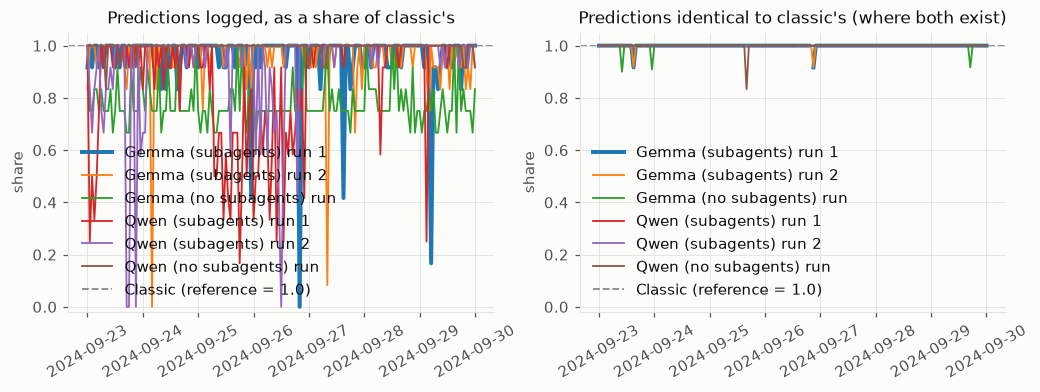

In [125]:
# coverage and agreement over time: one line per model, same axis
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), sharex=False)
for n, r in R.items():
    if r["per_hour"] is None:
        continue
    l = r["ph_last"].sort_values("hour")
    x = pd.to_datetime(l.hour)
    lw = 2.6 if n == list(R)[0] else 1.2          # first model thicker, so overlapping lines stay visible
    axes[0].plot(x, l.coverage_vs_classic, color=COLORS.get(n), label=n, lw=lw)
    pn = r["per_node"].copy(); pn["hour"] = pd.to_datetime(pn.hour)
    m = pn.groupby("hour").pred_match.apply(lambda s: s.dropna().astype(bool).mean())
    axes[1].plot(m.index, m.values, color=COLORS.get(n), label=n, lw=lw)

axes[0].set_title("Predictions logged, as a share of classic's"); axes[0].set_ylim(-0.02, 1.05)
axes[1].set_title("Predictions identical to classic's (where both exist)"); axes[1].set_ylim(-0.02, 1.05)
for a in axes:
    a.axhline(1.0, color=COLORS["Classic"], ls="--", lw=1.2, zorder=1, label="Classic (reference = 1.0)")
    a.set_ylabel("share"); a.legend(loc="lower left"); a.tick_params(axis="x", rotation=30)

## 2. Traffic classification agreement (essential)

Three levels, all compared with the classic verdict rules (a reference, not ground truth):

* **Detector (node):** per node and hour, `verdict_classic` vs `verdict_agent`.
* **Corridor:** one verdict per direction (`arrabida-freixo`, `freixo-arrabida`). Classic's value comes from the classic record;
  the agent's is derived with the same roll-up rule (`macro_drift` > `localized_event` > `within_baseline` > `pending`)
  from the node verdicts it reported, because the agent logs no corridor verdict of its own.
* **Network:** the overall verdict of the session (`log_run_summary.corridor_verdict` for the agent).

`not_reported` means the agent produced no verdict for that node or session.
Cohen's kappa is shown with and without trivial all-`pending` rows, and the class counts are shown
because kappa is unstable when almost every row is `within_baseline`.

In [126]:
NODE_LABELS = ["macro_drift", "localized_event", "within_baseline", "pending", "not_reported"]

def clean(v):
    m = re.match(r"(within_baseline|localized_event|macro_drift|pending)", str(v))
    return m.group(1) if m else "not_reported"
    # return "not_reported" if v is None or (isinstance(v, float) and np.isnan(v)) or v == "" else str(v)

def rollup(vs):
    for v in ("macro_drift", "localized_event", "within_baseline"):
        if v in vs:
            return v
    return "pending"

def node_to_label():
    m = {}
    for rec in CLASSIC.values():
        for lab, ns in rec.get("nodes", {}).items():
            for n in ns:
                m[n["node"]] = lab
    return m

def levels(r):
    pn = r["per_node"]; pn = pn[pn.verdict_classic.notna()]
    node = pd.DataFrame({"classic": pn.verdict_classic.map(clean), "agent": pn.verdict_agent.map(clean)})
    corr = pd.DataFrame(columns=["classic", "agent"])
    if CLASSIC:
        nl = node_to_label()
        t = pn.assign(label=pn.node.map(nl)).dropna(subset=["label"])
        rows = []
        for (hour, lab), g in t.groupby(["hour", "label"]):
            cv = CLASSIC.get(pd.Timestamp(hour).isoformat(), {}).get("corridor_verdicts", {}).get(lab)
            if cv:
                rows.append({"classic": cv, "agent": rollup([clean(v) for v in g.verdict_agent])})
        corr = pd.DataFrame(rows, columns=["classic", "agent"])
    l = r["ph_last"]
    net = pd.DataFrame({"classic": l.classic_overall_verdict.map(clean), "agent": l.agent_overall_verdict.map(clean)})
    return {"Detector (node)": node, "Corridor": corr, "Network (overall)": net}

def confusion(df):
    labs = [x for x in NODE_LABELS if x in set(df.classic) | set(df.agent)]
    labs += sorted((set(df.classic) | set(df.agent)) - set(labs))
    cat = pd.CategoricalDtype(labs)
    return pd.crosstab(df.classic.astype(cat), df.agent.astype(cat), dropna=False), labs

def kappa(df, labs):
    if df.empty or df.classic.nunique() < 1:
        return np.nan
    try:
        return round(cohen_kappa_score(df.classic, df.agent, labels=labs), 4)
    except Exception:
        return np.nan

def agreement_rows(r):
    out = {}
    for level, df in levels(r).items():
        if df.empty:
            continue
        cm, labs = confusion(df)
        nontrivial = df[~((df.classic == "pending") & df.agent.isin(["pending", "not_reported"]))]
        out[(level, "rows compared")] = len(df)
        out[(level, "raw agreement")] = round((df.classic == df.agent).mean(), 4)
        out[(level, "Cohen's kappa")] = kappa(df, labs)
        out[(level, "rows excluding trivial pending")] = len(nontrivial)
        out[(level, "raw agreement excluding trivial pending")] = round((nontrivial.classic == nontrivial.agent).mean(), 4) if len(nontrivial) else None
        out[(level, "Cohen's kappa excluding trivial pending")] = kappa(nontrivial, labs)
        out[(level, "agent verdict missing (not_reported)")] = int((df.agent == "not_reported").sum())
        for c in ("macro_drift", "localized_event"):
            sup = int((df.classic == c).sum())
            tp = int(((df.classic == c) & (df.agent == c)).sum())
            pred = int((df.agent == c).sum())
            out[(level, f"{c}: classic count / recall / precision")] = f"{sup} / {share(tp, sup)} / {share(tp, pred)}"
    return out

agree = pd.DataFrame({n: agreement_rows(r) for n, r in R.items() if r["per_node"] is not None})
agree.index.names = ["Level", "Metric"]
show(agree, "Verdict agreement with classic", "2_agreement")

**Verdict agreement with classic**

Gemma (subagents) run 1 Gemma (subagents) run 2 Gemma (no subagents) run Qwen (subagents) run 1 Qwen (subagents) run 2  \
Level             Metric                                                                                                                                                                       
Detector (node)   rows compared                                                          2028                    2028                     2016                   2028                   2028   
                  raw agreement                                                        0.5838                  0.5971                   0.0149                 0.7821                 0.9058   
                  Cohen's kappa                                                        0.0909                  0.1062                   0.0072                 0.2121                 0.4312   
                  rows excluding trivial pending                                         2016                    2016                     2004                   2016                   2016   
                  raw agreement excluding trivial pending                              0.5843                  0.5947                    0.009                 0.7808                 0.9053   
                  Cohen's kappa excluding trivial pending                              0.0795                  0.0878                   0.0013                 0.1854                 0.3929   
                  agent verdict missing (not_reported)                                    765                     797                     1980                     60                     59   
                  macro_drift: classic count / recall / precision             0 / None / None         0 / None / None          0 / None / None        0 / None / None        0 / None / None   
                  localized_event: classic count / recall / precision       73 / 0.4384 / 1.0       73 / 0.5205 / 1.0        73 / 0.0274 / 1.0      73 / 0.6438 / 1.0      73 / 0.8493 / 1.0   
Corridor          rows compared                                                           338                     338                      336                    338                    338   
                  raw agreement                                                        0.6479                  0.6243                   0.0149                 0.9172                  0.932   
                  Cohen's kappa                                                        0.3006                  0.3018                   0.0036                 0.7188                 0.7744   
                  rows excluding trivial pending                                          336                     336                      334                    336                    336   
                  raw agreement excluding trivial pending                              0.6458                   0.622                    0.009                 0.9167                 0.9315   
                  Cohen's kappa excluding trivial pending                              0.2909                  0.2933                   0.0035                 0.7092                 0.7668   
                  agent verdict missing (not_reported)                                      0                       0                        0                      0                      0   
                  macro_drift: classic count / recall / precision             0 / None / None         0 / None / None          0 / None / None        0 / None / None        0 / None / None   
                  localized_event: classic count / recall / precision       55 / 0.4727 / 1.0       55 / 0.5455 / 1.0        55 / 0.0182 / 1.0      55 / 0.7091 / 1.0      55 / 0.8182 / 1.0   
Network (overall) rows compared                                                           169                     169                      168                    169                    169   
                  raw agreement       

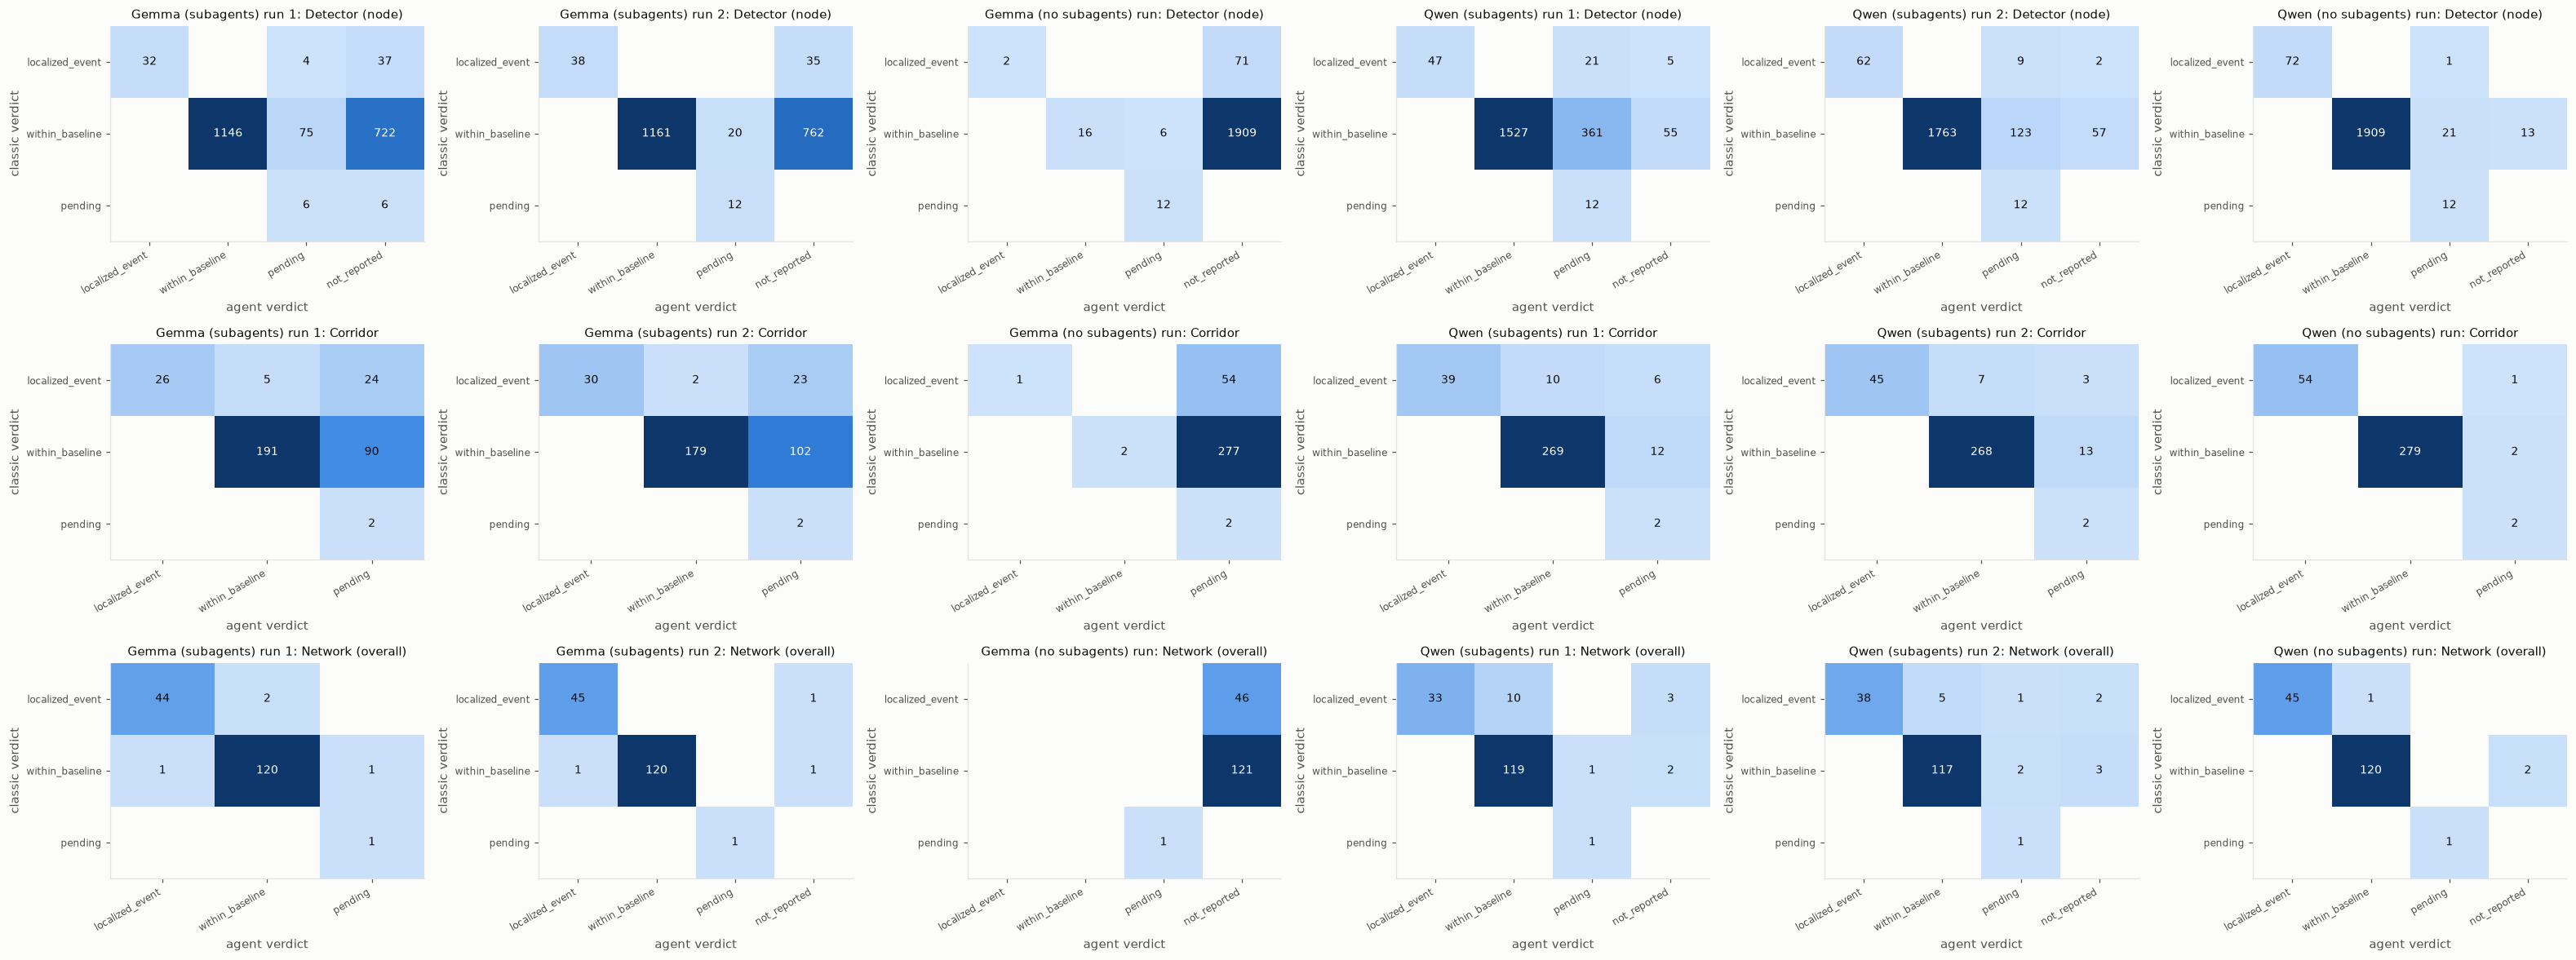

In [127]:
def draw_cm(ax, cm, title):
    cm = cm.loc[cm.sum(axis=1) > 0]                       # classic never produces some labels (e.g. not_reported)
    vals = cm.values.astype(float)
    cmap = SEQ.copy(); cmap.set_bad(SURFACE)               # zero cells stay empty, they are not "a little"
    ax.imshow(np.ma.masked_where(vals == 0, vals), cmap=cmap, vmin=0, vmax=max(vals.max(), 1), aspect="auto")
    ax.set_xticks(range(len(cm.columns))); ax.set_xticklabels(cm.columns, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(len(cm.index))); ax.set_yticklabels(cm.index, fontsize=8)
    ax.grid(False); ax.set_title(title, fontsize=10)
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            v = int(vals[i, j])
            ax.text(j, i, f"{v}" if v else "", ha="center", va="center", fontsize=9,
                    color="white" if vals[i, j] > 0.5 * max(vals.max(), 1) else INK)
    ax.set_xlabel("agent verdict"); ax.set_ylabel("classic verdict")

names = [n for n, r in R.items() if r["per_node"] is not None]
lv = {n: levels(R[n]) for n in names}
level_names = ["Detector (node)", "Corridor", "Network (overall)"]
fig, axes = plt.subplots(len(level_names), len(names), figsize=(4.8 * len(names), 3.6 * len(level_names)), squeeze=False)
for i, L in enumerate(level_names):
    for j, n in enumerate(names):
        df = lv[n][L]
        if df.empty:
            axes[i][j].axis("off"); continue
        cm, _ = confusion(df)
        cm.to_csv(OUT / f"2_confusion_{L.split()[0].lower()}_{n}.csv")
        draw_cm(axes[i][j], cm, f"{n}: {L}")
plt.tight_layout(); plt.show()

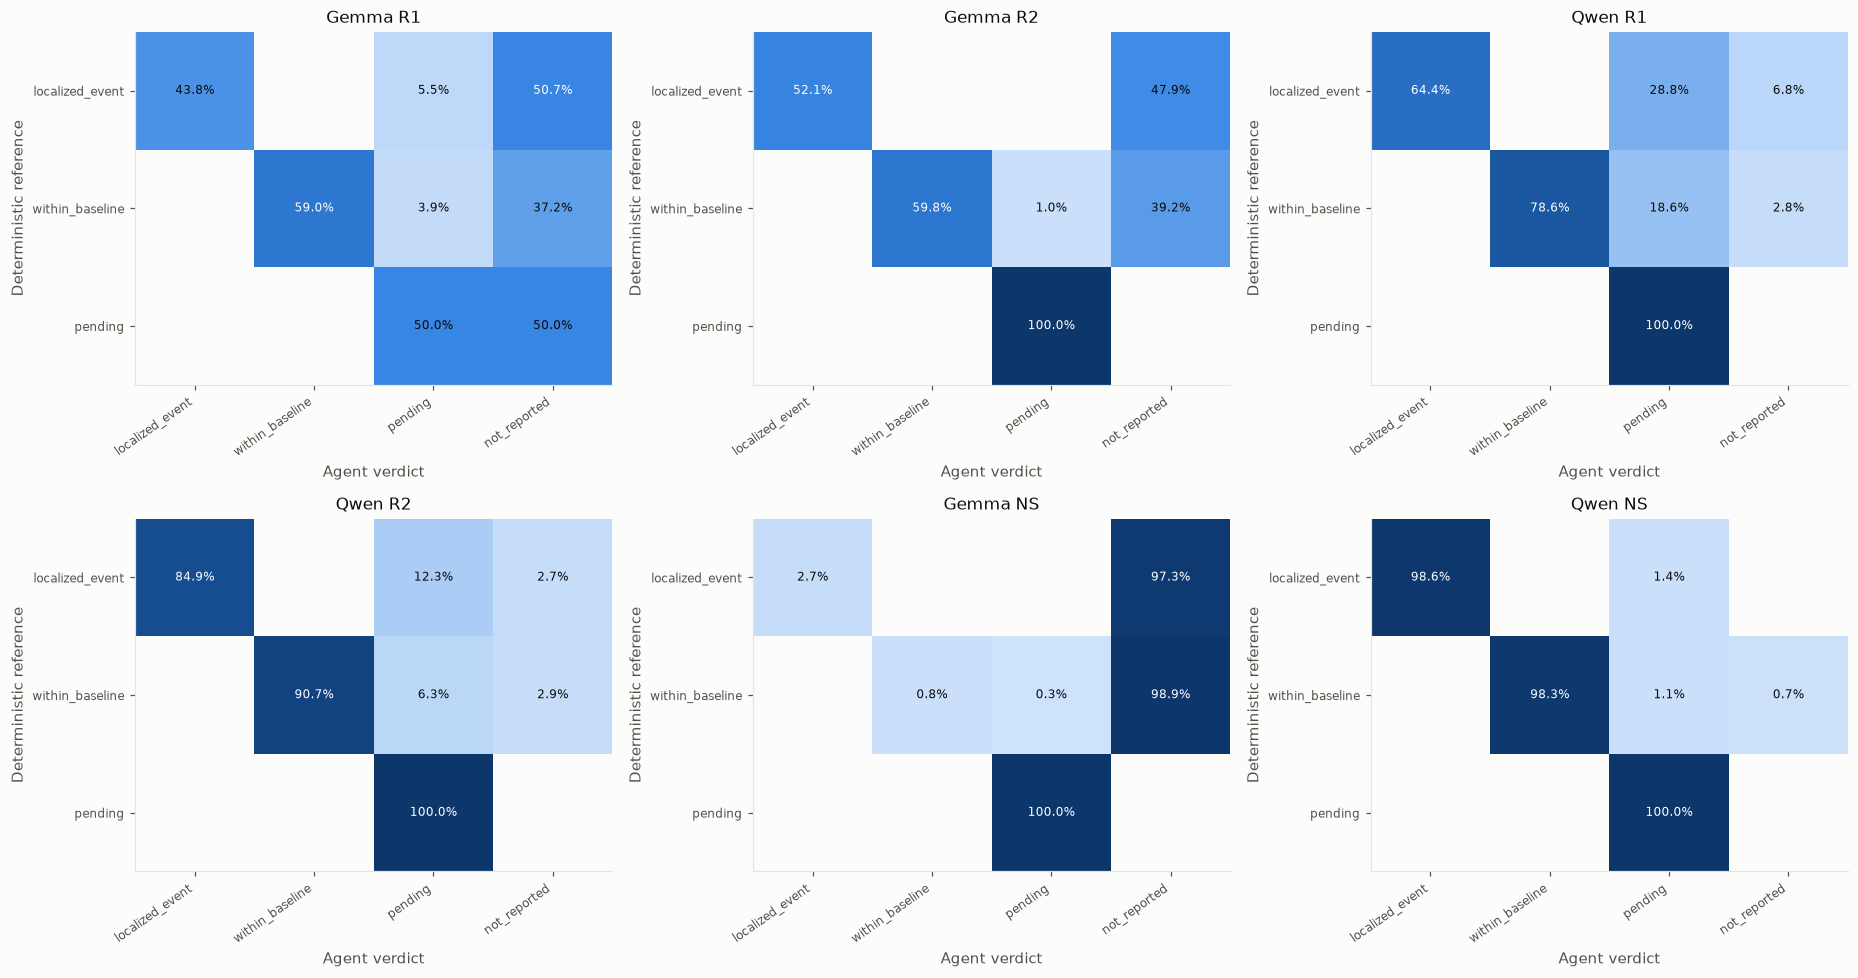

In [147]:
def draw_cm(ax, cm, title):
    # Remove reference classes with no observations
    cm = cm.loc[cm.sum(axis=1) > 0]

    # Normalize each reference-class row to percentages
    cm_pct = cm.div(cm.sum(axis=1), axis=0).fillna(0) * 100
    vals = cm_pct.values.astype(float)

    cmap = SEQ.copy()
    cmap.set_bad(SURFACE)

    im = ax.imshow(
        np.ma.masked_where(vals == 0, vals),
        cmap=cmap,
        vmin=0,
        vmax=100,
        aspect="auto"
    )

    ax.set_xticks(range(len(cm.columns)))
    ax.set_xticklabels(
        cm.columns, rotation=35, ha="right", fontsize=8
    )

    ax.set_yticks(range(len(cm.index)))
    ax.set_yticklabels(cm.index, fontsize=8)

    ax.grid(False)
    ax.set_title(title, fontsize=11)

    # Display percentages inside cells
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            v = vals[i, j]

            if v > 0:
                ax.text(
                    j, i, f"{v:.1f}%",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="white" if v > 50 else INK
                )

    ax.set_xlabel("Agent verdict")
    ax.set_ylabel("Deterministic reference")

    return im


# Explicit configuration order
names = [
    "Gemma (subagents) run 1",
    "Gemma (subagents) run 2",
    "Qwen (subagents) run 1",
    "Qwen (subagents) run 2",
    "Gemma (no subagents) run",
    "Qwen (no subagents) run"
]

titles = [
    "Gemma R1",
    "Gemma R2",
    "Qwen R1",
    "Qwen R2",
    "Gemma NS",
    "Qwen NS"
]

# Detector-level comparisons only
fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 9),
    squeeze=False
)

for ax, n, title in zip(axes.flat, names, titles):

    df = levels(R[n])["Detector (node)"]

    if df.empty:
        ax.axis("off")
        continue

    cm, _ = confusion(df)

    # Save original counts separately
    cm.to_csv(
        OUT / f"2_confusion_detector_{title.replace(' ', '_')}.csv"
    )

    # Plot normalized confusion matrix
    draw_cm(ax, cm, title)


plt.tight_layout()

# Save the figure used in the dissertation
from pathlib import Path

Path("figs").mkdir(exist_ok=True)

plt.savefig(
    "figs/confusion_detector.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 3. Failure and disagreement analysis (essential)

Explains *why* the agentic runs differ from the baseline: missing predictions, wrong tool arguments,
incomplete evaluations, classification disagreements and failed sessions.

In [128]:
def failed_sessions(r):
    t = r["timing"].set_index("hour"); l = r["ph_last"].set_index("hour")
    d = pd.DataFrame(index=t.index)
    d["seconds"] = t.seconds
    d["goose_exit"] = t.goose_exit.astype(str)
    d["nonzero_exit"] = d.goose_exit != "0"
    d["no_run_summary"] = ~l.log_run_summary_ok.astype(bool).reindex(d.index).fillna(False)
    d["no_final_ditto"] = ~l.log_final_ditto_ok.astype(bool).reindex(d.index).fillna(False)
    d["missing_predictions"] = l.missing_nodes.fillna("").map(lambda s: len(s.split())).reindex(d.index).fillna(0).astype(int)
    d["incomplete_evaluation"] = (l.eval_coverage_vs_classic.reindex(d.index) < 1).fillna(False)
    d["bad_eval_args"] = (l.check_deviation_bad_args.reindex(d.index).fillna(0) > 0)
    d["bad_payloads"] = (l.payload_bad_calls.reindex(d.index).fillna(0) > 0)
    calls = r["calls"]
    stalled = set(calls[calls.latency_s > STALL_S].hour)
    d["stalled_request"] = d.index.isin(stalled)
    d["tool_errors"] = l.tool_errors.reindex(d.index).fillna(0).astype(int)
    return d

fs = {n: failed_sessions(r) for n, r in R.items() if r["per_hour"] is not None}
summary = {}
for n, d in fs.items():
    n_s = len(d)
    summary[n] = {
        "sessions": n_s,
        "goose exit code != 0": int(d.nonzero_exit.sum()),
        "no run summary logged": int(d.no_run_summary.sum()),
        "no final Ditto record": int(d.no_final_ditto.sum()),
        "sessions with missing predictions": int((d.missing_predictions > 0).sum()),
        "missing prediction node-hours": int(d.missing_predictions.sum()),
        "sessions with incomplete evaluations": int(d.incomplete_evaluation.sum()),
        "sessions with wrong check_deviation arguments": int(d.bad_eval_args.sum()),
        "sessions with wrong baseline_predict payloads": int(d.bad_payloads.sum()),
        f"sessions with a request slower than {STALL_S}s": int(d.stalled_request.sum()),
        "sessions with tool errors": int((d.tool_errors > 0).sum()),
        "sessions with no problem at all": int((~(d.nonzero_exit | d.no_run_summary | d.no_final_ditto | (d.missing_predictions > 0)
                                                  | d.incomplete_evaluation | d.bad_eval_args | d.bad_payloads | d.stalled_request)).sum()),
    }
show(pd.DataFrame(summary), "Session-level failure summary", "3_failure_summary")
for n, d in fs.items():
    d.to_csv(OUT / f"3_sessions_{n}.csv")

**Session-level failure summary**

,Gemma (subagents) run 1,Gemma (subagents) run 2,Gemma (no subagents) run,Qwen (subagents) run 1,Qwen (subagents) run 2,Qwen (no subagents) run
sessions,169,169,169,169,169,169
goose exit code != 0,0,0,2,0,0,0
no run summary logged,0,2,168,5,5,2
no final Ditto record,0,2,168,5,5,2
sessions with missing predictions,52,52,156,73,43,10
missing prediction node-hours,92,90,444,274,148,11
sessions with incomplete evaluations,58,16,167,88,38,13
sessions with wrong check_deviation arguments,0,0,0,8,3,1
sessions with wrong baseline_predict payloads,96,101,164,15,9,75
sessions with a request slower than 300s,12,13,6,0,0,1


In [129]:
# which nodes are missed, and what kind of wrong arguments occur
for n, r in R.items():
    if r["per_node"] is None:
        continue
    d = disagreements(r)
    valid = {"within_baseline", "localized_event", "macro_drift", "pending", "not_reported"}
    d["malformed"] = ~d.verdict_agent.isin(valid)
    show(d.groupby(["likely_cause", "malformed"]).size().rename("node-hours").to_frame(),
         f"{n}: causes split by malformed verdict string")
    
    miss = Counter(x for s in r["ph_last"].missing_nodes.fillna("") for x in s.split())
    iss = Counter(x for s in r["per_node"].payload_issues.fillna("") for x in s.split())
    c1 = pd.DataFrame(miss.most_common(15), columns=["node", "hours missed"]).set_index("node")
    c2 = pd.DataFrame(iss.most_common(15), columns=["payload issue", "count"]).set_index("payload issue")
    show(c1, f"{n}: most frequently missing predictions (hours missed)", f"3_missing_nodes_{n}")
    show(c2, f"{n}: wrong-payload issue types in baseline_predict", f"3_payload_issues_{n}")

**Gemma (subagents) run 1: causes split by malformed verdict string**

,,node-hours
likely_cause,malformed,
agent reported no verdict (evaluation or summary missing),False,765
different verdict although inputs matched (rule applied differently),False,29
previous-hour prediction differed from classic (different baseline),False,72


**Gemma (subagents) run 1: most frequently missing predictions (hours missed)**

,hours missed
node,
716_1.0,10
741_-1.0,10
719_-1.0,9
3_1.0,9
722_1.0,9
716_-1.0,8
718_-1.0,8
718_1.0,7
741_1.0,6


**Gemma (subagents) run 1: wrong-payload issue types in baseline_predict**

...

,,node-hours
likely_cause,malformed,
agent reported no verdict (evaluation or summary missing),False,13
different verdict although inputs matched (rule applied differently),False,1
previous-hour prediction differed from classic (different baseline),False,21


**Qwen (no subagents) run: most frequently missing predictions (hours missed)**

,hours missed
node,
722_1.0,2
718_-1.0,2
741_1.0,2
741_-1.0,1
718_1.0,1
722_-1.0,1
3_1.0,1
716_-1.0,1


**Qwen (no subagents) run: wrong-payload issue types in baseline_predict**

,count
payload issue,
wrong_value:flows_24,42
wrong_value:flows_168,41
wrong_value:flows_1,35
wrong_timestamp,11
wrong_value:precipitation,2
wrong_value:temperature,2


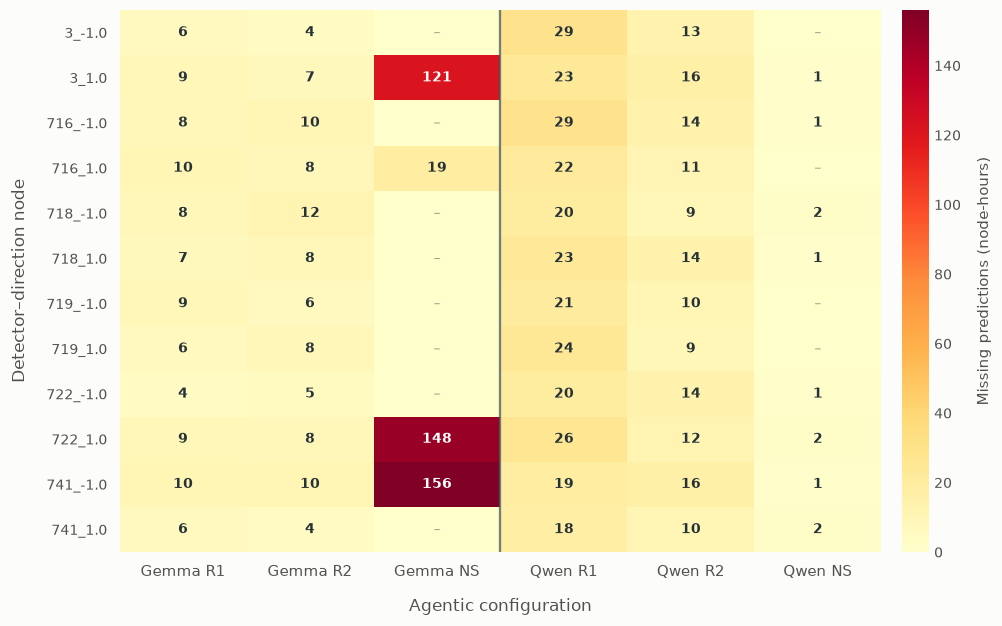

In [131]:
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle
from pathlib import Path

# --------------------------------------------------
# Data
# --------------------------------------------------

nodes = sorted({
    x
    for r in R.values()
    if r["ph_last"] is not None
    for s in r["ph_last"].missing_nodes.fillna("")
    for x in s.split()
})

M = pd.DataFrame({
    short(n): Counter(
        x
        for s in r["ph_last"].missing_nodes.fillna("")
        for x in s.split()
    )
    for n, r in R.items()
    if r["ph_last"] is not None
}).reindex(nodes).fillna(0).astype(int)

# Optional: arrange configurations consistently
preferred_order = [
    "Gemma R1",
    "Gemma R2",
    "Gemma NS",
    "Qwen R1",
    "Qwen R2",
    "Qwen NS",
]

order = [c for c in preferred_order if c in M.columns]
order += [c for c in M.columns if c not in order]

M = M[order]

# --------------------------------------------------
# Plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(9.2, 5.8))

cmap = plt.get_cmap("YlOrRd")
norm = Normalize(vmin=0, vmax=max(1, M.values.max()))

im = ax.imshow(
    M.values,
    cmap=cmap,
    norm=norm,
    aspect="auto",
    interpolation="nearest"
)

# Axis labels
ax.set_xticks(np.arange(M.shape[1]))
ax.set_xticklabels(
    M.columns,
    fontsize=10,
    fontweight="medium"
)

ax.set_yticks(np.arange(M.shape[0]))
ax.set_yticklabels(
    M.index,
    fontsize=9
)

ax.set_xlabel("Agentic configuration", fontsize=11, labelpad=12)
ax.set_ylabel("Detector–direction node", fontsize=11, labelpad=12)

# Remove tick marks
ax.tick_params(axis="both", which="both", length=0, pad=8)

# Subtle white cell borders
ax.set_xticks(np.arange(-0.5, M.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-0.5, M.shape[0], 1), minor=True)

ax.grid(
    which="minor",
    color="white",
    linewidth=1.8
)

ax.tick_params(which="minor", bottom=False, left=False)

# Values inside cells
for i in range(M.shape[0]):
    for j in range(M.shape[1]):

        value = M.iat[i, j]

        ax.text(
            j, i,
            f"{value:d}" if value else "–",
            ha="center",
            va="center",
            fontsize=9,
            fontweight="semibold" if value else "normal",
            color=(
                "white"
                if norm(value) > 0.62
                else "#263238"
            ),
            alpha=1 if value else 0.45
        )

# Separator between Gemma and Qwen
if M.shape[1] == 6:
    ax.axvline(
        2.5,
        color="#455A64",
        linewidth=1.5,
        alpha=0.75
    )

# Remove outer spines
for spine in ax.spines.values():
    spine.set_visible(False)

# Colourbar
cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.035,
    pad=0.025
)

cbar.set_label(
    "Missing predictions (node-hours)",
    fontsize=10,
    labelpad=10
)

cbar.ax.tick_params(labelsize=9, length=0)
cbar.outline.set_visible(False)
# Remove all grid lines
ax.grid(False, which="both")

# Disable minor ticks
ax.minorticks_off()
fig.tight_layout()

Path("figures").mkdir(exist_ok=True)

fig.savefig(
    "figures/missed_nodes.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [132]:
# classification disagreements, with the most likely cause
def disagreements(r):
    pn = r["per_node"]; l = r["ph_last"].set_index("hour")
    d = pn[pn.verdict_classic.notna()].copy()
    d["verdict_agent"] = d.verdict_agent.map(clean)
    d = d[d.verdict_classic != d.verdict_agent]
    bad_eval = l.check_deviation_bad_args.reindex(d.hour).fillna(0).values > 0
    def cause(row, be):
        if row.verdict_agent == "not_reported":
            return "agent reported no verdict (evaluation or summary missing)"
        if be:
            return "session had wrong check_deviation arguments"
        if not bool(row.prev_hour_prediction_matched):
            return "previous-hour prediction differed from classic (different baseline)"
        return "different verdict although inputs matched (rule applied differently)"
    d["likely_cause"] = [cause(row, be) for row, be in zip(d.itertuples(), bad_eval)]
    return d

for n, r in R.items():
    if r["per_node"] is None:
        continue
    d = disagreements(r)
    tot = int(r["per_node"].verdict_classic.notna().sum())
    c = d.likely_cause.value_counts().to_frame("node-hours")
    c["share of disagreements"] = (c["node-hours"] / max(len(d), 1)).round(3)
    show(c, f"{n}: {len(d)} disagreements out of {tot} node-hours", f"3_disagreement_causes_{n}")
    pair = d.groupby(["verdict_classic", "verdict_agent"]).size().rename("node-hours").to_frame()
    show(pair, f"{n}: which verdicts were confused", f"3_disagreement_pairs_{n}")
    cols = ["hour", "node", "verdict_classic", "verdict_agent", "likely_cause", "classic_prediction", "agent_prediction", "actual_flow"]
    d[cols].to_csv(OUT / f"3_disagreements_{n}.csv", index=False)

**Gemma (subagents) run 1: 844 disagreements out of 2028 node-hours**

,node-hours,share of disagreements
likely_cause,,
agent reported no verdict (evaluation or summary missing),765,0.906
previous-hour prediction differed from classic (different baseline),72,0.085
different verdict although inputs matched (rule applied differently),7,0.008


**Gemma (subagents) run 1: which verdicts were confused**

node-hours
verdict_classic verdict_agent            
localized_event not_reported           37
                pending                 4
pending         not_reported            6
within_baseline not_reported          722
                pending                75

**Gemma (subagents) run 2: 817 disagreements out of 2028 node-hours**

...

node-hours
verdict_classic verdict_agent            
localized_event not_reported            2
                pending                 9
within_baseline not_reported           57
                pending               123

**Qwen (no subagents) run: 35 disagreements out of 2028 node-hours**

,node-hours,share of disagreements
likely_cause,,
previous-hour prediction differed from classic (different baseline),21,0.600
agent reported no verdict (evaluation or summary missing),13,0.371
different verdict although inputs matched (rule applied differently),1,0.029


**Qwen (no subagents) run: which verdicts were confused**

node-hours
verdict_classic verdict_agent            
localized_event pending                 1
within_baseline not_reported           13
                pending                21

In [133]:
# tool errors per tool (from the MCP trace) and error strings found in the goose session logs
LOG_PATTERNS = {
    "5-background-task cap refused a delegate": "Maximum 5 background",
    "rate limit error reached the agent": "Rate limit exceeded",
    "delegate source not found": "not found. Use load()",
    "missing required parameters": "Missing required parameters",
    "agent hit its action limit": "maximum number of actions",
}

def trace_errors(r):
    t = r["trace"]
    if t.empty:
        return None
    t = t.assign(is_call=t.phase.eq("CALL"), is_err=t.phase.eq("ERROR"))
    g = t.groupby("tool")
    out = pd.DataFrame({"calls": g.is_call.sum(), "errors": g.is_err.sum()})
    out["answered"] = t[~t.is_call].groupby("tool").size().reindex(out.index).fillna(0).astype(int)
    out["unanswered"] = (out.calls - out.answered).clip(lower=0)
    out["error_rate"] = (out.errors / out.calls.replace(0, np.nan)).round(4)
    return out.sort_values("errors", ascending=False)

def log_errors(r):
    d = r["path"] / "logs"
    if not d.is_dir():
        return None
    rows = {}
    for p in d.glob("*.log"):
        text = p.read_text(errors="ignore")
        rows[p.stem] = {k: text.count(v) for k, v in LOG_PATTERNS.items()}
    return pd.DataFrame(rows).T

for n, r in R.items():
    te = trace_errors(r)
    if te is not None:
        show(te, f"{n}: MCP tool calls and errors (trace.jsonl)", f"3_tool_errors_{n}")
        err_msgs = r["trace"][r["trace"].phase.eq("ERROR")].extra.astype(str).str.slice(0, 90).value_counts().head(10)
        if len(err_msgs):
            show(err_msgs.to_frame("count"), f"{n}: most common error messages", f"3_error_messages_{n}")
    le = log_errors(r)
    if le is not None:
        tot = pd.DataFrame({"occurrences": le.sum(), "sessions affected": (le > 0).sum()})
        show(tot, f"{n}: error strings in the goose session logs ({len(le)} logs)", f"3_log_errors_{n}")
    ph = r["per_hour"]
    if ph is not None and "log_delegate_calls" in ph:
        extra = {"delegate calls": int(ph.log_delegate_calls.sum()),
                 "sessions where the coordinator called pipeline tools itself": int((ph.log_coordinator_direct_tool_calls > 0).sum()),
                 "subagent `load` instead of tools": int(ph.log_subagent_load_misuse.sum())}
        show(pd.Series(extra).to_frame("value"), f"{n}: delegation behaviour (from compare.py)", f"3_delegation_{n}")

**Gemma (subagents) run 1: MCP tool calls and errors (trace.jsonl)**

,calls,errors,answered,unanswered,error_rate
tool,,,,,
baseline_predict,2101,151,2101,0,0.0719
get_pending_prediction,2020,2,2020,0,0.0010
log_final_ditto,170,1,170,0,0.0059
build_summary_table,257,0,257,0,0.0000
get_actual_flow,1918,0,1918,0,0.0000
check_deviation,1907,0,1907,0,0.0000
get_corridor_status,338,0,338,0,0.0000
get_current_timestamp,169,0,169,0,0.0000
get_flows,1994,0,1994,0,0.0000


**Gemma (subagents) run 1: most common error messages**

,count
extra,
Incomplete flows_payload for 719_-1.0: missing fields ['precipitation']. Pass the complete,15
Incomplete flows_payload for 3_1.0: missing fields ['precipitation']. Pass the complete re,13
Incomplete flows_payload for 716_1.0: missing fields ['precipitation']. Pass the complete,13
Incomplete flows_payload for 716_-1.0: missing fields ['precipitation']. Pass the complete,12
Incomplete flows_payload for 741_1.0: missing fields ['precipitation']. Pass the complete,11
Incomplete flows_payload for 741_-1.0: missing fields ['precipitation']. Pass the complete,11
Incomplete flows_payload for 719_1.0: missing fields ['precipitation']. Pass the complete,8
Incomplete flows_payload for 722_-1.0: missing fields ['precipitation']. Pass the complete,7
Incomplete flows_payload for 718_1.0: missing fields ['precipitation']. Pass the complete,7


**Gemma (subagents) run 1: error strings in the goose session logs (169 logs)**

...

,count
extra,
Prediction computed but could not be persisted to historic Ditto:,2
Could not fetch actual flow for 3_1.0 at 2024-09-25T18:00:00:,1
Prediction lookup failed:,1
"Prediction failed for 722_-1.0: NaN features: ['Avg_Temperature', 'Avg_Precipitation']",1
"Unknown datetime string format, unable to parse: 2024-09-29T03:0 match",1
"Prediction failed for 716_-1.0: NaN features: ['Avg_Temperature', 'Avg_Precipitation']",1


**Qwen (no subagents) run: error strings in the goose session logs (169 logs)**

,occurrences,sessions affected
5-background-task cap refused a delegate,0,0
rate limit error reached the agent,0,0
delegate source not found,0,0
missing required parameters,0,0
agent hit its action limit,0,0


**Qwen (no subagents) run: delegation behaviour (from compare.py)**

,value
delegate calls,0
sessions where the coordinator called pipeline tools itself,169
subagent `load` instead of tools,0


## 4. Execution time (essential)

Wall time per hourly session from `timing.csv`, against the classic pipeline's own run time
(`classic_total_s` in `per_hour.csv`). *Typical* excludes sessions that contain one stalled LLM request.

In [134]:
# Sessions independently confirmed to have been interrupted
# by laptop sleep during the Gemma no-subagent experiment.

GEMMA_NS = "Gemma (no subagents) run"

gemma_ns_timing = R[GEMMA_NS]["timing"].copy()

exit_codes = pd.to_numeric(
    gemma_ns_timing["goose_exit"],
    errors="coerce"
)

# Identify sessions with a nonzero Goose exit code.
interrupted_mask = exit_codes.notna() & exit_codes.ne(0)

interrupted_sessions = gemma_ns_timing.loc[
    interrupted_mask,
    ["hour", "seconds", "goose_exit"]
]

print("Sessions interrupted by laptop sleep:")
display(interrupted_sessions)

assert interrupted_mask.sum() == 2, (
    "Expected exactly two interrupted sessions. "
    "Check the exit codes before filtering."
)

print(f"Original sessions: {len(gemma_ns_timing)}")
print(f"Uninterrupted sessions: {(~interrupted_mask).sum()}")

Sessions interrupted by laptop sleep:


,hour,seconds,goose_exit
102,2024-09-27T06:00:00,34657,1
164,2024-09-29T20:00:00,4072,1


Original sessions: 169
Uninterrupted sessions: 167


In [135]:
def dist(s):
    s = num(s).dropna()
    if s.empty:
        return {}
    return {
        "n": int(len(s)),
        "mean": s.mean(),
        "std": s.std(),
        "median": s.median(),
        "p90": s.quantile(.90),
        "p95": s.quantile(.95),
        "p99": s.quantile(.99),
        "max": s.max(),
        "total_hours": s.sum() / 3600
    }
GEMMA_NS = "Gemma (no subagents) run"

rows = {}

for n, r in R.items():
    t = r["timing"]
    calls = r["calls"]

    stalled = set(
        calls[calls.latency_s > 3600].hour
    )

    if n == GEMMA_NS:

        exit_codes = pd.to_numeric(
            t["goose_exit"],
            errors="coerce"
        )

        interrupted = (
            exit_codes.notna()
            & exit_codes.ne(0)
        )

        assert interrupted.sum() == 2

        uninterrupted_t = t.loc[~interrupted]

        rows[f"{n} (uninterrupted)"] = dist(
            uninterrupted_t.seconds
        )


classic_s = None

for r in R.values():
    if (
        r.get("ph_last") is not None
        and r["ph_last"].classic_total_s.notna().any()
    ):
        classic_s = num(
            r["ph_last"].classic_total_s
        )
        break


if classic_s is not None:
    rows["Classic (deterministic)"] = dist(classic_s)


tt = pd.DataFrame(rows).T.round(1)

show(
    tt,
    "Seconds per hourly session",
    "4_execution_time"
)

**Seconds per hourly session**

,n,mean,std,median,p90,p95,p99,max,total_hours
Gemma (no subagents) run (uninterrupted),167.0,424.8,609.1,346.0,383.4,401.2,2249.2,7652.0,19.7
Classic (deterministic),169.0,17.6,1.5,17.5,19.3,21.0,22.3,24.2,0.8


In [136]:
def dist(s):
    s = num(s).dropna()
    if s.empty:
        return {}
    return {"n": int(len(s)), "mean": s.mean(), "std": s.std(), "median": s.median(),
            "p90": s.quantile(.90), "p95": s.quantile(.95), "p99": s.quantile(.99), "max": s.max(), "total_hours": s.sum() / 3600}

rows = {}
for n, r in R.items():
    t = r["timing"]; calls = r["calls"]
    stalled = set(calls[calls.latency_s > STALL_S].hour)
    rows[f"{n} (all sessions)"] = dist(t.seconds)
    rows[f"{n} (typical, no stalled request)"] = dist(t[~t.hour.isin(stalled)].seconds)
classic_s = None
for r in R.values():
    if r.get("ph_last") is not None and r["ph_last"].classic_total_s.notna().any():
        classic_s = num(r["ph_last"].classic_total_s); break
if classic_s is not None:
    rows["Classic (deterministic)"] = dist(classic_s)
tt = pd.DataFrame(rows).T.round(1)
show(tt, "Seconds per hourly session", "4_execution_time")

if classic_s is not None:
    ratio = {}
    for n, r in R.items():
        a = num(r["timing"].seconds)
        ratio[n] = {"mean x classic": round(a.mean() / classic_s.mean(), 1), "median x classic": round(a.median() / classic_s.median(), 1)}
    show(pd.DataFrame(ratio).T, "Agent time as a multiple of classic", "4_time_ratio")

feas = {}
for n, r in R.items():
    s = num(r["timing"].seconds)
    feas[n] = {"sessions": len(s), f"finished within {FEASIBLE_S // 60} min": share(int((s <= FEASIBLE_S).sum()), len(s)),
               "finished within 10 min": share(int((s <= 600).sum()), len(s)),
               "slower than the hourly slot": int((s > FEASIBLE_S).sum()), "slowest (min)": round(s.max() / 60, 1),
               "hourly operation feasible (max < slot)": bool(s.max() < FEASIBLE_S)}
show(pd.DataFrame(feas).T, "Feasibility of hourly operation", "4_feasibility")

**Seconds per hourly session**

,n,mean,std,median,p90,p95,p99,max,total_hours
Gemma (subagents) run 1 (all sessions),169.0,363.4,288.0,281.0,370.2,1255.0,1505.2,1815.0,17.1
"Gemma (subagents) run 1 (typical, no stalled request)",157.0,286.1,40.5,279.0,322.6,352.6,453.4,498.0,12.5
Gemma (subagents) run 2 (all sessions),169.0,370.5,312.4,290.0,361.2,1158.2,1705.2,2508.0,17.4
"Gemma (subagents) run 2 (typical, no stalled request)",156.0,289.1,33.1,286.5,332.5,346.0,372.8,406.0,12.5
Gemma (no subagents) run (all sessions),169.0,648.9,2714.9,347.0,384.4,437.6,5217.6,34657.0,30.5
"Gemma (no subagents) run (typical, no stalled request)",163.0,361.2,171.6,346.0,374.6,389.9,519.1,2500.0,16.4
Qwen (subagents) run 1 (all sessions),169.0,280.4,21.2,281.0,300.0,308.6,334.4,354.0,13.2
"Qwen (subagents) run 1 (typical, no stalled request)",169.0,280.4,21.2,281.0,300.0,308.6,334.4,354.0,13.2
Qwen (subagents) run 2 (all sessions),169.0,341.5,140.7,292.0,443.8,572.0,996.4,1315.0,16.0
"Qwen (subagents) run 2 (typical, no stalled request)",169.0,341.5,140.7,292.0,443.8,572.0,996.4,1315.0,16.0


**Agent time as a multiple of classic**

,mean x classic,median x classic
Gemma (subagents) run 1,20.6,16.0
Gemma (subagents) run 2,21.0,16.6
Gemma (no subagents) run,36.8,19.8
Qwen (subagents) run 1,15.9,16.0
Qwen (subagents) run 2,19.3,16.7
Qwen (no subagents) run,24.2,22.8


**Feasibility of hourly operation**

,sessions,finished within 60 min,finished within 10 min,slower than the hourly slot,slowest (min),hourly operation feasible (max < slot)
Gemma (subagents) run 1,169,1.0,0.929,0,30.2,True
Gemma (subagents) run 2,169,1.0,0.9231,0,41.8,True
Gemma (no subagents) run,169,0.9822,0.9527,3,577.6,False
Qwen (subagents) run 1,169,1.0,1.0,0,5.9,True
Qwen (subagents) run 2,169,1.0,0.9527,0,21.9,True
Qwen (no subagents) run,169,1.0,0.8757,0,19.6,True


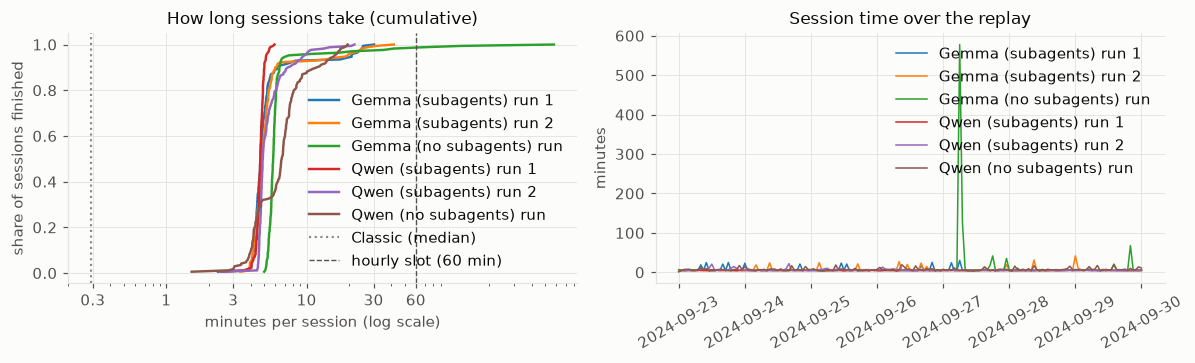

In [137]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for n, r in R.items():
    s = np.sort(num(r["timing"].seconds).dropna().values)
    axes[0].plot(s / 60, np.arange(1, len(s) + 1) / len(s), color=COLORS.get(n), label=n)
    t = r["timing"].copy(); t["h"] = pd.to_datetime(t.hour)
    axes[1].plot(t.h, num(t.seconds) / 60, color=COLORS.get(n), lw=1.0, label=n)
if classic_s is not None:
    axes[0].axvline(classic_s.median() / 60, color=COLORS["Classic"], ls=":", lw=1.4, label="Classic (median)")
axes[0].axvline(FEASIBLE_S / 60, color=INK2, ls="--", lw=0.9, label=f"hourly slot ({FEASIBLE_S // 60} min)")
axes[0].set_xscale("log")                                  # classic is ~10x faster, a linear axis would squash everything
axes[0].set_xticks([0.3, 1, 3, 10, 30, 60]); axes[0].xaxis.set_minor_formatter(plt.NullFormatter())
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
axes[0].set_xlabel("minutes per session (log scale)"); axes[0].set_ylabel("share of sessions finished")
axes[0].set_title("How long sessions take (cumulative)"); axes[0].legend(loc="lower right")
axes[1].set_ylabel("minutes"); axes[1].set_title("Session time over the replay"); axes[1].legend(loc="upper right")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

In [138]:
logs_dir = Path(
    "no_subagents/runs_no_subagents/gemma-4-26b-a4b_nosub/logs"
)

pattern = "maximum number of actions"

affected = []

for path in logs_dir.rglob("*"):
    if not path.is_file():
        continue

    try:
        content = path.read_text(
            encoding="utf-8",
            errors="replace"
        )

        if pattern.lower() in content.lower():
            affected.append({
                "session": path.stem,
                "file": str(path),
                "occurrences": content.lower().count(pattern)
            })

    except OSError:
        continue

action_limit_df = pd.DataFrame(affected)

print("Session logs with action-limit message:", len(action_limit_df))

if not action_limit_df.empty:
    print(
        "Distinct session identifiers:",
        action_limit_df["session"].nunique()
    )

    print(
        "Total occurrences in session logs:",
        action_limit_df["occurrences"].sum()
    )

    display(action_limit_df.head())

Session logs with action-limit message: 164
Distinct session identifiers: 164
Total occurrences in session logs: 164


,session,file,occurrences
0,2024-09-26T23-00-00,no_subagents/runs_no_subagents/gemma-4-26b-a4b_nosub/logs/2024-09-26T23-00-0...,1
1,2024-09-23T23-00-00,no_subagents/runs_no_subagents/gemma-4-26b-a4b_nosub/logs/2024-09-23T23-00-0...,1
2,2024-09-28T14-00-00,no_subagents/runs_no_subagents/gemma-4-26b-a4b_nosub/logs/2024-09-28T14-00-0...,1
3,2024-09-26T13-00-00,no_subagents/runs_no_subagents/gemma-4-26b-a4b_nosub/logs/2024-09-26T13-00-0...,1
4,2024-09-29T13-00-00,no_subagents/runs_no_subagents/gemma-4-26b-a4b_nosub/logs/2024-09-29T13-00-0...,1


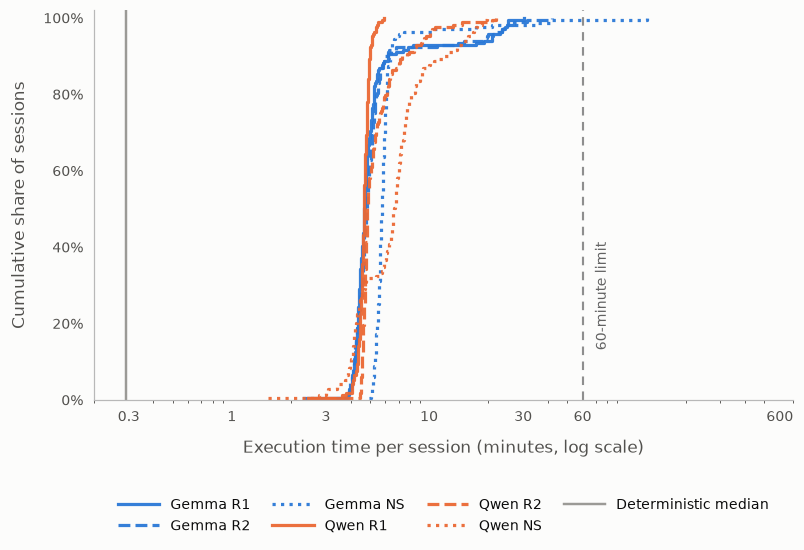

In [139]:
def model_of(n):
    return "Gemma" if n.startswith("Gemma") else "Qwen"

def short(n):
    model = model_of(n)
    if "no subagents" in n:
        return f"{model} NS"
    return f"{model} R{n[-1]}"

LINESTYLES = {
    "R1": "-",
    "R2": "--",
    "NS": ":",
}

def style_of(n):
    if "no subagents" in n:
        return LINESTYLES["NS"]
    return LINESTYLES[f"R{n[-1]}"]


# --------------------------------------------------
# Plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8.2, 4.6))

# Order lines by model and configuration
preferred_order = [
    "Gemma (subagents) run 1",
    "Gemma (subagents) run 2",
    "Gemma (no subagents) run",
    "Qwen (subagents) run 1",
    "Qwen (subagents) run 2",
    "Qwen (no subagents) run",
]

ordered_runs = (
    [n for n in preferred_order if n in R]
    + [n for n in R if n not in preferred_order]
)

for n in ordered_runs:

    r = R[n]

    t = r["timing"].copy()

    if n == "Gemma (no subagents) run":
        exits = pd.to_numeric(t["goose_exit"], errors="coerce")
        t = t.loc[exits.isna() | exits.eq(0)]

    times = np.sort(
        num(t.seconds).dropna().to_numpy()
    ) / 60

    if len(times) == 0:
        continue

    ecdf = np.arange(1, len(times) + 1) / len(times)

    ax.step(
        times,
        ecdf,
        where="post",
        color=COLORS[model_of(n)],
        linestyle=style_of(n),
        linewidth=2.1,
        alpha=0.95,
        label=short(n),
    )


# --------------------------------------------------
# Reference lines
# --------------------------------------------------

classic_median = classic_s.median() / 60
hourly_limit = FEASIBLE_S / 60

# Deterministic baseline
ax.axvline(
    classic_median,
    color=COLORS["Classic"],
    linestyle="-",
    linewidth=1.6,
    alpha=0.85,
    label="Deterministic median",
)

# Hourly feasibility threshold
ax.axvline(
    hourly_limit,
    color="#737373",
    linestyle=(0, (4, 3)),
    linewidth=1.4,
    alpha=0.8,
)

ax.annotate(
    "60-minute limit",
    xy=(hourly_limit, 0.13),
    xytext=(8, 0),
    textcoords="offset points",
    rotation=90,
    va="bottom",
    ha="left",
    fontsize=9,
    color="#626262",
)


# --------------------------------------------------
# Axis formatting
# --------------------------------------------------

ax.set_xscale("log")

ax.set_xlim(0.2, 700)
ax.set_ylim(0, 1.02)

ax.set_xticks(
    [0.3, 1, 3, 10, 30, 60, 600]
)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:g}")
)

ax.xaxis.set_minor_formatter(NullFormatter())

ax.set_yticks(np.linspace(0, 1, 6))

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:.0%}")
)

ax.set_xlabel(
    "Execution time per session (minutes, log scale)",
    fontsize=11,
    labelpad=10,
)

ax.set_ylabel(
    "Cumulative share of sessions",
    fontsize=11,
    labelpad=10,
)

ax.tick_params(
    axis="both",
    labelsize=9,
    length=0,
    pad=7,
)

# No grid
ax.grid(False, which="both")

# Minimal spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Keep y-axis visible
ax.spines["left"].set_visible(True)
ax.spines["left"].set_color("#B8B8B8")
ax.spines["left"].set_linewidth(0.8)

ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_color("#B8B8B8")
ax.spines["bottom"].set_linewidth(0.8)

# --------------------------------------------------
# Legend
# --------------------------------------------------

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=4,
    frameon=False,
    fontsize=9,
    columnspacing=1.6,
    handlelength=3,
)

# --------------------------------------------------
# Export
# --------------------------------------------------

Path("figures").mkdir(exist_ok=True)

fig.savefig(
    "figures/ecdf_time.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

## 5. LLM resource consumption (important)

From `llm_calls.jsonl` (one line per request, usage as reported by the server). Every request is one agent turn,
including requests made by subagents. goose counts `GOOSE_MAX_TURNS` per agent, and the log does not say which agent
sent a request, so requests per session are an upper bound on any single agent's turns. `max_messages / 2` is shown as
an approximation of the longest conversation (usually the coordinator).

In [140]:
def per_session(r):
    c = r["calls"].copy()
    c["is_retried"] = c.retries.fillna(0) > 0
    c["is_trunc"] = c.finish_reason.eq("length")
    c["is_runaway"] = c.completion_tokens > RUNAWAY_TOKENS
    c["runaway_tokens"] = c.completion_tokens.where(c.is_runaway, 0)
    c["over_limit"] = c.prompt_tokens > CONTEXT_LIMIT
    c["over_80"] = c.prompt_tokens > 0.8 * CONTEXT_LIMIT
    c["failed"] = ~c.status.between(200, 299) | c.error.notna()
    g = c.groupby("hour")
    s = pd.DataFrame({
        "requests": g.size(), "input_tokens": g.prompt_tokens.sum(min_count=1), "output_tokens": g.completion_tokens.sum(min_count=1),
        "max_prompt_tokens": g.prompt_tokens.max(), "max_messages": g.n_messages.max(),
        "retried": g.is_retried.sum(), "truncated": g.is_trunc.sum(), "runaway_tokens": g.runaway_tokens.sum(),
        "summarize_flagged": g.summarize_hint.sum(), "over_limit": g.over_limit.sum(), "over_80": g.over_80.sum(),
        "failed": g.failed.sum(), "mean_latency_s": g.latency_s.mean(),
    })
    s["output_excl_runaway"] = s.output_tokens - s.runaway_tokens
    return s.reindex(r["timing"].hour)

PS = {n: per_session(r) for n, r in R.items()}
for n, s in PS.items():
    s.to_csv(OUT / f"5_per_session_{n}.csv")

def resource(n, r):
    s, c = PS[n], r["calls"]
    d = {}
    for col, label in (("requests", "LLM requests per session (turns incl. subagents)"),
                       ("input_tokens", "input tokens per session"), ("output_tokens", "output tokens per session"),
                       ("output_excl_runaway", f"output tokens per session excl. responses > {RUNAWAY_TOKENS}")):
        for k, v in dist(s[col]).items():
            if k in ("mean", "median", "p90", "max"):
                d[(label, k)] = round(v, 1)
    d[("tokens per request", "mean input")] = round(c.prompt_tokens.mean(), 1)
    d[("tokens per request", "median output")] = round(c.completion_tokens.median(), 1)
    d[("tokens per request", "p99 output")] = round(c.completion_tokens.quantile(.99), 1)
    d[("totals", "input tokens")] = int(c.prompt_tokens.sum()); d[("totals", "output tokens")] = int(c.completion_tokens.sum())
    d[("totals", "LLM requests")] = len(c)
    d[("totals", "usage reported by the server")] = round((c.usage_source == "server").mean(), 4)
    d[("totals", "prompt tokens served from cache (if reported)")] = (
        round(c.cached_tokens.sum() / c.prompt_tokens.sum(), 4) if c.cached_tokens.notna().any() else "not reported")
    d[(f"context (limit {CONTEXT_LIMIT})", "largest prompt (tokens)")] = int(c.prompt_tokens.max())
    d[(f"context (limit {CONTEXT_LIMIT})", "largest prompt as % of limit")] = round(100 * c.prompt_tokens.max() / CONTEXT_LIMIT, 1)
    d[(f"context (limit {CONTEXT_LIMIT})", "requests above 80% of limit")] = int((c.prompt_tokens > .8 * CONTEXT_LIMIT).sum())
    d[(f"context (limit {CONTEXT_LIMIT})", "requests above the limit")] = int((c.prompt_tokens > CONTEXT_LIMIT).sum())
    d[(f"context (limit {CONTEXT_LIMIT})", "sessions with a request above the limit")] = int((s.over_limit > 0).sum())
    d[("summarisation", "requests flagged as summarise (heuristic: no tools + 'summar')")] = int(c.summarize_hint.sum())
    d[("summarisation", "sessions with a flagged request")] = int((s.summarize_flagged > 0).sum())
    d[(f"turns (max {MAX_TURNS})", "sessions with requests >= max turns")] = int((s.requests >= MAX_TURNS).sum())
    d[(f"turns (max {MAX_TURNS})", "longest conversation, approx. turns (max_messages / 2)")] = round(s.max_messages.max() / 2, 1)
    d[("errors and stalls", "LLM requests failed or errored")] = int(s.failed.sum())
    d[("errors and stalls", "requests retried after 429/503")] = int(s.retried.sum())
    d[("errors and stalls", "responses cut off (finish_reason=length)")] = int(s.truncated.sum())
    d[("errors and stalls", "output tokens in runaway responses")] = int(s.runaway_tokens.sum())
    d[("errors and stalls", "share of all output tokens")] = round(s.runaway_tokens.sum() / max(c.completion_tokens.sum(), 1), 4)
    d[("errors and stalls", f"requests slower than {STALL_S}s")] = int((c.latency_s > STALL_S).sum())
    d[("errors and stalls", "mean request latency (s)")] = round(c.latency_s.mean(), 2)
    if r["per_hour"] is not None:
        te = r["ph_last"].tool_errors
        d[("errors and stalls", "MCP tool errors (total)")] = int(te.sum())
        d[("errors and stalls", "sessions with an MCP tool error")] = int((te > 0).sum())
    return d

res = pd.DataFrame({n: resource(n, r) for n, r in R.items()})
res.index.names = ["Area", "Metric"]
show(res, "LLM resource consumption", "5_resources")

**LLM resource consumption**

Gemma (subagents) run 1  Gemma (subagents) run 2  Gemma (no subagents) run  \
Area                                              Metric                                                                                                                                       
LLM requests per session (turns incl. subagents)  mean                                                                       1.253000e+02             1.241000e+02              1.479000e+02   
                                                  median                                                                     1.230000e+02             1.230000e+02              1.500000e+02   
                                                  p90                                                                        1.480000e+02             1.492000e+02              1.500000e+02   
                                                  max                                                                        2.410000e+02             1.600000e+02              1.510000e+02   
input tokens per session                          mean                                                                       1.012977e+06             1.021277e+06              1.820241e+06   
                                                  median                                                                     1.018923e+06             1.000812e+06              1.844833e+06   
                                                  p90                                                                        1.349296e+06             1.444805e+06              1.888430e+06   
                                                  max                                                                        1.942808e+06             1.676950e+06              1.927619e+06   
output tokens per session                         mean                                                                       5.138320e+04             5.116300e+04              3.988030e+04   
                                                  median                                                                     4.305700e+04             4.457400e+04              3.869200e+04   
                                                  p90                                                                        4.989140e+04             5.082320e+04              4.257460e+04   
                                                  max                                                                        1.834420e+05             2.058140e+05              1.509490e+05   
output tokens per session excl. responses > 20000 mean                                                                       4.391290e+04             4.383600e+04              3.848460e+04   
                                                  median                                                                     4.289300e+04             4.413300e+04              3.859200e+04   
                                                  p90                                                                        4.759080e+04             4.852300e+04              4.243820e+04   
                                                  max                                                                        9.044700e+04             5.724100e+04              5.729000e+04   
tokens per request                                mean input                                                                 8.098800e+03             8.232200e+03              1.231270e+04   
                                                  median output                                                              2.510000e+02             2.500000e+02              1.490000e+02   
                                                  p99 output                                                                 3.141000e+03             3.224800e+03              3.007200e+03   
totals                                            input tokens                    

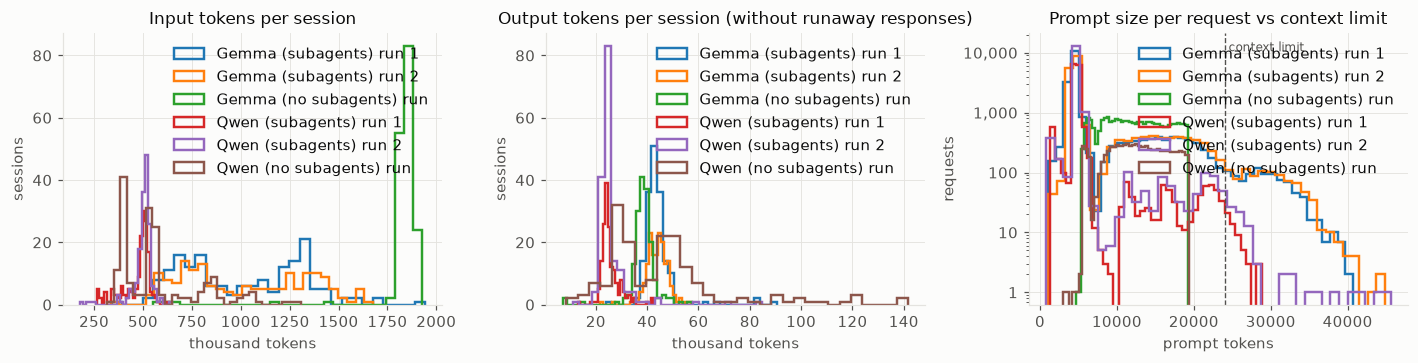

In [141]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
def hist(ax, getter, bins, title, xlabel, logy=False):
    for n in R:
        x = getter(n).dropna()
        ax.hist(x, bins=bins, histtype="step", lw=1.6, color=COLORS.get(n), label=n)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("sessions" if not logy else "requests")
    if logy:
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
        ax.yaxis.set_minor_formatter(plt.NullFormatter())
    ax.legend()
hist(axes[0], lambda n: PS[n].input_tokens / 1e3, 30, "Input tokens per session", "thousand tokens")
hist(axes[1], lambda n: PS[n].output_excl_runaway / 1e3, 30, "Output tokens per session (without runaway responses)", "thousand tokens")
hist(axes[2], lambda n: R[n]["calls"].prompt_tokens, 40, "Prompt size per request vs context limit", "prompt tokens", logy=True)
axes[2].axvline(CONTEXT_LIMIT, color=INK2, ls="--", lw=0.9)
axes[2].text(CONTEXT_LIMIT, 0.97, " context limit", transform=axes[2].get_xaxis_transform(), color=INK2, fontsize=8, va="top")
plt.tight_layout(); plt.show()

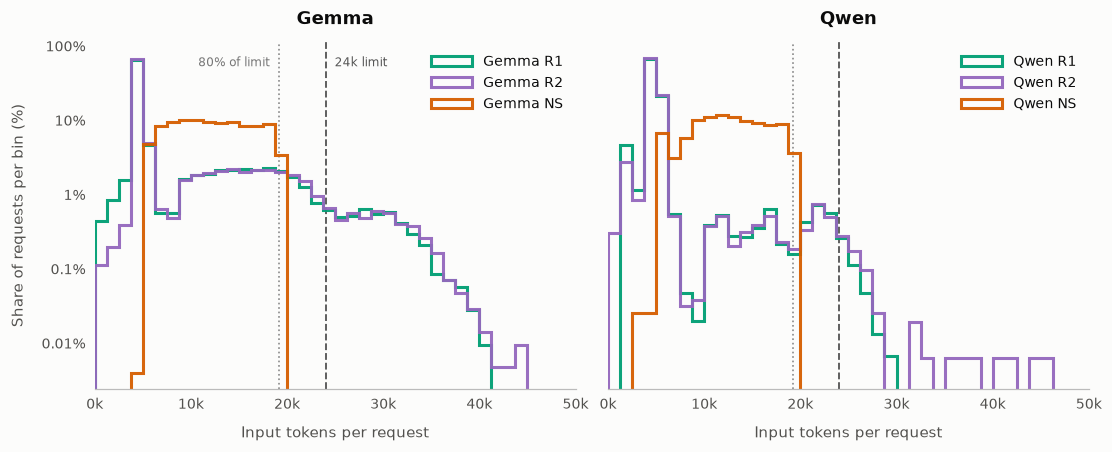

In [142]:
# --------------------------------------------------
# Colors: one color per run
# --------------------------------------------------

RUN_COLORS = {
    "R1": "#009E73",  # Teal
    "R2": "#9467BD",  # Purple
    "NS": "#D55E00",  # Coral
}

def color_of(n):
    if "no subagents" in n.lower():
        return RUN_COLORS["NS"]
    return RUN_COLORS[f"R{n[-1]}"]


# --------------------------------------------------
# Data and figure
# --------------------------------------------------

bins = np.arange(0, 50001, 1250)

fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 4.0),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for ax, model in zip(axes, ["Gemma", "Qwen"]):

    model_runs = [
        (n, r)
        for n, r in R.items()
        if model_of(n) == model
    ]

    for n, r in model_runs:

        tokens = (
            num(r["calls"].prompt_tokens)
            .dropna()
            .to_numpy()
        )

        if len(tokens) == 0:
            continue

        # Normalize histogram to percentages
        weights = np.full(
            len(tokens),
            100 / len(tokens)
        )

        ax.hist(
            tokens,
            bins=bins,
            weights=weights,
            histtype="step",
            linewidth=2.0,
            linestyle="-",
            color=color_of(n),
            alpha=0.95,
            label=short(n)
        )

    # --------------------------------------------------
    # Reference limits
    # --------------------------------------------------

    ax.axvline(
        0.8 * CONTEXT_LIMIT,
        color="#8A8A8A",
        linewidth=1.1,
        linestyle=":",
        zorder=1
    )

    ax.axvline(
        CONTEXT_LIMIT,
        color="#555555",
        linewidth=1.2,
        linestyle="--",
        zorder=1
    )

    # --------------------------------------------------
    # Styling
    # --------------------------------------------------

    ax.set_title(
        model,
        fontsize=12,
        fontweight="semibold",
        pad=12
    )

    ax.set_xlabel(
        "Input tokens per request",
        fontsize=10,
        labelpad=9
    )

    ax.set_xlim(0, 50000)

    ax.set_xticks(
        [0, 10000, 20000, 30000, 40000, 50000]
    )

    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, _: f"{x/1000:.0f}k")
    )

    ax.tick_params(
        axis="both",
        labelsize=9,
        length=0,
        pad=6
    )

    ax.grid(False, which="both")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    ax.spines["bottom"].set_color("#BBBBBB")

    ax.legend(
        loc="upper right",
        fontsize=9,
        frameon=False,
        handlelength=3
    )


# --------------------------------------------------
# Shared Y-axis
# --------------------------------------------------

axes[0].set_ylabel(
    "Share of requests per bin (%)",
    fontsize=10,
    labelpad=10
)

# Keep logarithmic scale for differences in frequencies
axes[0].set_yscale("log")

axes[0].yaxis.set_major_formatter(
    FuncFormatter(lambda y, _: f"{y:g}%")
)

axes[0].yaxis.set_minor_locator(NullLocator())


# --------------------------------------------------
# Threshold annotations
# --------------------------------------------------

axes[0].annotate(
    "80% of limit",
    xy=(0.8 * CONTEXT_LIMIT, 0.96),
    xycoords=axes[0].get_xaxis_transform(),
    xytext=(-6, 0),
    textcoords="offset points",
    ha="right",
    va="top",
    fontsize=8,
    color="#777777"
)

axes[0].annotate(
    "24k limit",
    xy=(CONTEXT_LIMIT, 0.96),
    xycoords=axes[0].get_xaxis_transform(),
    xytext=(6, 0),
    textcoords="offset points",
    ha="left",
    va="top",
    fontsize=8,
    color="#555555"
)


# --------------------------------------------------
# Export
# --------------------------------------------------

Path("figures").mkdir(exist_ok=True)

fig.savefig(
    "figures/prompt_size.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [148]:
# ---- tokens per session, per stored prediction, and which conversations exceed the context limit ----
SHORT_CONV_MAX_MSGS = 20      # heuristic: a delegated subagent (max 8 turns) stays below about 20 messages
N_NODES = 12                  # active detector-direction nodes

def token_table():
    cols = {}
    for n, r in R.items():
        c = r["calls"]
        if c.empty or c.prompt_tokens.notna().sum() == 0:
            continue
        sess = r["timing"].hour.nunique()
        g = c.groupby("hour")
        inp, out = g.prompt_tokens.sum(min_count=1), g.completion_tokens.sum(min_count=1)
        pn = r["per_node"]
        stored = int(pn.agent_prediction.notna().sum()) if pn is not None else 0
        cols[n] = {
            "requests / session (mean)": len(c) / sess,
            "input tokens / session, mean": inp.mean(),
            "input tokens / session, median": inp.median(),
            "input tokens / session, p90": inp.quantile(0.9),
            "input tokens / session, max": inp.max(),
            "output tokens / session, mean": out.mean(),
            "output tokens / session, median": out.median(),
            "output tokens / session, p90": out.quantile(0.9),
            "output tokens / session, max": out.max(),
            "input tokens / request, mean": c.prompt_tokens.mean(),
            "output tokens / request, median": c.completion_tokens.median(),
            "input tokens / active node (mean session / 12)": inp.mean() / N_NODES,
            "stored predictions": stored,
            "input tokens / stored prediction": c.prompt_tokens.sum() / stored if stored else np.nan,
            "output tokens / stored prediction": c.completion_tokens.sum() / stored if stored else np.nan,
        }
    t = pd.DataFrame(cols).round(0)
    cached = {n: (R[n]["calls"].cached_tokens.sum() / R[n]["calls"].prompt_tokens.sum())
              if R[n]["calls"].cached_tokens.notna().any() else np.nan for n in cols}
    t.loc["cached share of input tokens"] = pd.Series(cached).round(3)
    return t

TT = token_table()
show(TT, "Tokens per session, per request and per stored prediction", "5_tokens_per_session")

def conversation_split():
    cols = {}
    for n, r in R.items():
        c = r["calls"]
        if c.empty or c.prompt_tokens.notna().sum() == 0:
            continue
        long_c = c.n_messages > SHORT_CONV_MAX_MSGS
        over = c.prompt_tokens > CONTEXT_LIMIT
        cols[n] = {
            "requests": len(c),
            "requests in long conversations": int(long_c.sum()),
            "requests in short conversations": int((~long_c).sum()),
            f"over {CONTEXT_LIMIT} tokens, long conversations": int((over & long_c).sum()),
            f"over {CONTEXT_LIMIT} tokens, short conversations": int((over & ~long_c).sum()),
            "largest prompt, long conversations": c.loc[long_c, "prompt_tokens"].max(),
            "largest prompt, short conversations": c.loc[~long_c, "prompt_tokens"].max(),
            "requests flagged as summarisation": int(c.summarize_hint.sum()),
            "sessions with >= max turns requests": int((c.groupby("hour").size() >= MAX_TURNS).sum()),
        }
    return pd.DataFrame(cols)

show(conversation_split(),
     "Where the over-limit prompts come from (heuristic: more than 20 messages = coordinator-like; "
     "meaningful only for runs with subagents)", "5_conversation_split")

**Tokens per session, per request and per stored prediction**

,Gemma (subagents) run 1,Gemma (subagents) run 2,Gemma (no subagents) run,Qwen (subagents) run 1,Qwen (subagents) run 2,Qwen (no subagents) run
requests / session (mean),125.000,124.000,148.000,92.000,98.000,46.00
"input tokens / session, mean",1012977.000,1021277.000,1820241.000,470362.000,499074.000,582668.00
"input tokens / session, median",1018923.000,1000812.000,1844833.000,499383.000,509486.000,538930.00
"input tokens / session, p90",1349296.000,1444805.000,1888430.000,531513.000,536311.000,874173.00
"input tokens / session, max",1942808.000,1676950.000,1927619.000,633934.000,649193.000,1309275.00
"output tokens / session, mean",51383.000,51163.000,39880.000,25588.000,26054.000,51263.00
"output tokens / session, median",43057.000,44574.000,38692.000,24648.000,24338.000,48253.00
"output tokens / session, p90",49891.000,50823.000,42575.000,30376.000,30012.000,85485.00
"output tokens / session, max",183442.000,205814.000,150949.000,42338.000,84922.000,150990.00
"input tokens / request, mean",8099.000,8232.000,12313.000,5307.000,5383.000,12678.00


**Where the over-limit prompts come from (heuristic: more than 20 messages = coordinator-like; meaningful only for runs with subagents)**

,Gemma (subagents) run 1,Gemma (subagents) run 2,Gemma (no subagents) run,Qwen (subagents) run 1,Qwen (subagents) run 2,Qwen (no subagents) run
requests,21182.0,20981.0,24988.0,15472.0,16601.0,7768.0
requests in long conversations,5386.0,5351.0,18654.0,750.0,786.0,4635.0
requests in short conversations,15796.0,15630.0,6334.0,14722.0,15815.0,3133.0
"over 24000 tokens, long conversations",936.0,957.0,0.0,55.0,88.0,0.0
"over 24000 tokens, short conversations",0.0,0.0,0.0,0.0,0.0,0.0
"largest prompt, long conversations",40684.0,44806.0,19252.0,28823.0,45607.0,19315.0
"largest prompt, short conversations",11548.0,12385.0,12963.0,9081.0,9582.0,19294.0
requests flagged as summarisation,0.0,0.0,498.0,0.0,47.0,338.0
sessions with >= max turns requests,14.0,17.0,164.0,0.0,1.0,0.0


## 6. Five-year cost comparison (important)

Fill in the two parameter cells, then run the rest. The token numbers come from section 5, so they are measured, not assumed.

* **Local:** hardware capex amortised over the 5 years and divided by the number of runs (electricity ignored, as agreed).
* **API:** price per million tokens x measured tokens per run x number of runs.
* **Break-even:** the number of runs at which the API bill equals the hardware cost.
* Three token scenarios: *observed* (runaway responses included), *runaways removed* (the realistic target once outputs are capped)
  and *capped* (every response limited to `OUTPUT_CAP` tokens).

In [143]:
RUNS_PER_HOUR = 1
YEARS = 5
N_RUNS = 24 * 365 * YEARS * RUNS_PER_HOUR          # 43,800 hourly runs

HARDWARE_COST = 6000      # hardware cost of local
CURRENCY = "USD"
OUTPUT_CAP = 4096         # tokens, used by the 'capped' scenario

# price per million tokens; providers / models
# cached_in is optional (price of cached input tokens); None = no cache discount applied.

# https://openrouter.ai/compare/qwen/qwen3.8-27b/google/gemma-4-26b-a4b-it
API = {
    # "Provider model": {"in": 0.30, "out": 2.50, "cached_in": 0.03},
    "Qwen": {
        "in": 0.020,
        "out": 0.500,
        "cached_in": 0.009,
    },
    "Gemma": {
        "in": 0.042,
        "out": 0.220,
        "cached_in": 0.021,
    },
}

In [144]:
def token_scenarios(r):
    c = r["calls"]; sessions = r["timing"].hour.nunique()
    obs_in, obs_out = c.prompt_tokens.sum() / sessions, c.completion_tokens.sum() / sessions
    run = c[~(c.completion_tokens > RUNAWAY_TOKENS)]
    cap = c.completion_tokens.clip(upper=OUTPUT_CAP)
    cached = (c.cached_tokens.sum() / c.prompt_tokens.sum()) if c.cached_tokens.notna().any() else 0.0
    return {
        "observed": (obs_in, obs_out),
        "runaways removed": (run.prompt_tokens.sum() / sessions, run.completion_tokens.sum() / sessions),
        f"output capped at {OUTPUT_CAP}": (obs_in, cap.sum() / sessions),
    }, cached

rows = []
for n, r in R.items():
    sc, cached = token_scenarios(r)
    for name, (i, o) in sc.items():
        rows.append({"model": n, "scenario": name, "input tokens / run": round(i), "output tokens / run": round(o),
                     "input tokens, 5 years (millions)": round(i * N_RUNS / 1e6, 1),
                     "output tokens, 5 years (millions)": round(o * N_RUNS / 1e6, 1), "cached share of prompt": round(cached, 3)})
tok = pd.DataFrame(rows).set_index(["model", "scenario"])
show(tok, f"Measured tokens per run and over {N_RUNS:,} runs", "6_tokens")

**Measured tokens per run and over 43,800 runs**

input tokens / run  output tokens / run  input tokens, 5 years (millions)  output tokens, 5 years (millions)  cached share of prompt
model                    scenario                                                                                                                                                   
Gemma (subagents) run 1  observed                          1012977                51383                           44368.4                             2250.6                   0.863
                         runaways removed                  1011232                43913                           44292.0                             1923.4                   0.863
                         output capped at 4096             1012977                43557                           44368.4                             1907.8                   0.863
Gemma (subagents) run 2  observed                          1021277                51163                           44731.9                             2240.9                   0.865
                         runaways removed                  1019764                43836                           44665.7                             1920.0                   0.865
                         output capped at 4096             1021277                43396                           44731.9                             1900.7                   0.865
Gemma (no subagents) run observed                          1820241                39880                           79726.6                             1746.8                   0.971
                         runaways removed                  1820085                38485                           79719.7                             1685.6                   0.971
                         output capped at 4096             1820241                38225                           79726.6                             1674.2                   0.971
Qwen (subagents) run 1   observed                           470362                25588                           20601.8                             1120.8                   0.219
                         runaways removed                   470362                25588                           20601.8                             1120.8                   0.219
                         output capped at 4096              470362                25017                           20601.8                             1095.7                   0.219
Qwen (subagents) run 2   observed                           499074                26054                           21859.4                             1141.2                   0.206
                         runaways removed                   499074                26054                           21859.4                             1141.2                   0.206
                         output capped at 4096              499074                25425                           21859.4                             1113.6                   0.206
Qwen (no subagents) run  observed                           582668                51263                           25520.8                             2245.3                   0.930
                         runaways removed                   580434                46128                           25423.0                             2020.4                   0.930
                         output capped at 4096              582668                28560                           25520.8                             1250.9                   0.930

**Five-year cost: local hardware vs API**

API cost per run (USD)  API cost, 5 years (USD)  local cost per run (USD)  local cost, 5 years (USD)  break-even (runs)  \
model                    scenario              provider                                                                                                                            
Gemma (subagents) run 1  observed              Qwen                      0.0363                     1591                     0.137                       6000             165138   
                                               Gemma                     0.0355                     1554                     0.137                       6000             169071   
                         runaways removed      Qwen                      0.0326                     1427                     0.137                       6000             184163   
                                               Gemma                     0.0338                     1481                     0.137                       6000             177499   
                         output capped at 4096 Qwen                      0.0324                     1420                     0.137                       6000             185070   
                                               Gemma                     0.0338                     1479                     0.137                       6000             177692   
Gemma (subagents) run 2  observed              Qwen                      0.0363                     1590                     0.137                       6000             165320   
                                               Gemma                     0.0356                     1560                     0.137                       6000             168515   
                         runaways removed      Qwen                      0.0326                     1428                     0.137                       6000             183970   
                                               Gemma                     0.0340                     1487                     0.137                       6000             176694   
                         output capped at 4096 Qwen                      0.0324                     1420                     0.137                       6000             185130   
                                               Gemma                     0.0339                     1485                     0.137                       6000             177011   
Gemma (no subagents) run observed              Qwen                      0.0369                     1616                     0.137                       6000             162598   
                                               Gemma                     0.0481                     2107                     0.137                       6000             124732   
                         runaways removed      Qwen                      0.0362                     1586                     0.137                       6000             165739   
                                               Gemma                     0.0478                     2093                     0.137                       6000             125542   
                         output capped at 4096 Qwen                      0.0361                     1580                     0.137                       6000             166329   
                                               Gemma                     0.0477                     2091                     0.137                       6000             125684   
Qwen (subagents) run 1   observed              Qwen                      0.0211                      923                     0.137                       6000             284809   
                                               Gemma                     0.0232                     1017                     0.137                       6000             258415   
                         runaways removed      Qwen                      0.0211                  

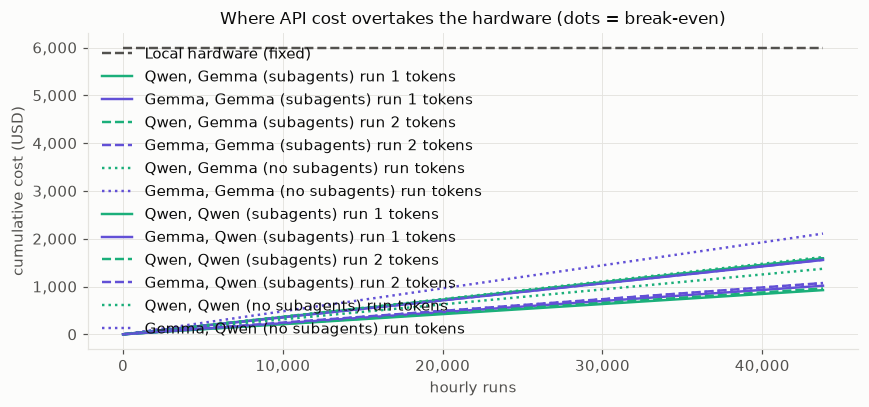

In [145]:
if HARDWARE_COST is None or not API:
    display(Markdown("**Set `HARDWARE_COST` and at least one entry in `API` in the cell above, then re-run this cell.**"))
else:
    rows = []
    local_per_run = HARDWARE_COST / N_RUNS
    for n, r in R.items():
        sc, cached = token_scenarios(r)
        for scen, (i, o) in sc.items():
            for prov, p in API.items():
                cin = p["in"]
                if p.get("cached_in") is not None and cached > 0:
                    cin = cached * p["cached_in"] + (1 - cached) * p["in"]
                per_run = (i * cin + o * p["out"]) / 1e6
                rows.append({"model": n, "scenario": scen, "provider": prov,
                             f"API cost per run ({CURRENCY})": round(per_run, 4),
                             f"API cost, {YEARS} years ({CURRENCY})": round(per_run * N_RUNS),
                             f"local cost per run ({CURRENCY})": round(local_per_run, 4),
                             f"local cost, {YEARS} years ({CURRENCY})": round(HARDWARE_COST),
                             "break-even (runs)": round(HARDWARE_COST / per_run) if per_run else None,
                             "break-even (years at 1 run/hour)": round(HARDWARE_COST / per_run / (24 * 365 * RUNS_PER_HOUR), 2) if per_run else None,
                             "cheaper over 5 years": "local" if HARDWARE_COST < per_run * N_RUNS else "API"})
    cost = pd.DataFrame(rows).set_index(["model", "scenario", "provider"])
    show(cost, "Five-year cost: local hardware vs API", "6_cost")

    fig, ax = plt.subplots(figsize=(8, 3.8))
    x = np.linspace(0, N_RUNS, 100)
    ax.plot(x, np.full_like(x, HARDWARE_COST), color=INK2, ls="--", label="Local hardware (fixed)")
    # colour = API provider (fixed order), line style = which model's measured tokens are priced; observed scenario
    PROV_COLORS = ["#1baf7a", "#6250d6", "#e87ba4", "#008300"]
    STYLES = ["-", "--", ":"]
    models = list(R)
    for (n, scen, prov), row in cost.iterrows():
        if scen != "observed":
            continue
        per_run = row[f"API cost per run ({CURRENCY})"]
        color = PROV_COLORS[list(API).index(prov) % len(PROV_COLORS)]
        ax.plot(x, x * per_run, color=color, ls=STYLES[models.index(n) % 3], label=f"{prov}, {n} tokens")
        be = HARDWARE_COST / per_run
        if be <= N_RUNS:
            ax.plot([be], [HARDWARE_COST], "o", ms=6, color=color, mec=SURFACE, mew=1.5, zorder=5)
    ax.set_xlabel("hourly runs"); ax.set_ylabel(f"cumulative cost ({CURRENCY})")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax.set_title("Where API cost overtakes the hardware (dots = break-even)")
    ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

## Export

Everything above was saved as CSV in `analysis_out/`. This cell lists what was written.

In [146]:
for p in sorted(OUT.glob("*.csv")):
    print(f"{p.stat().st_size:>9,d}  {p}")

    2,787  analysis_out/1_fidelity.csv
    2,724  analysis_out/2_agreement.csv
      109  analysis_out/2_confusion_corridor_Gemma (no subagents) run.csv
      111  analysis_out/2_confusion_corridor_Gemma (subagents) run 1.csv
      112  analysis_out/2_confusion_corridor_Gemma (subagents) run 2.csv
      109  analysis_out/2_confusion_corridor_Qwen (no subagents) run.csv
      111  analysis_out/2_confusion_corridor_Qwen (subagents) run 1.csv
      110  analysis_out/2_confusion_corridor_Qwen (subagents) run 2.csv
      152  analysis_out/2_confusion_detector_Gemma (no subagents) run.csv
      154  analysis_out/2_confusion_detector_Gemma (subagents) run 1.csv
      155  analysis_out/2_confusion_detector_Gemma (subagents) run 2.csv
      153  analysis_out/2_confusion_detector_Qwen (no subagents) run.csv
      155  analysis_out/2_confusion_detector_Qwen (subagents) run 1.csv
      154  analysis_out/2_confusion_detector_Qwen (subagents) run 2.csv
      149  analysis_out/2_confusion_network_Gem